# Clearview Properties — Residential Price Analysis

**Technical notebook.** It documents the whole analysis end to end for the Clearview Properties brief: data quality review, exploratory analysis, modeling, and the evidence behind each decision.

The client's questions:

| # | Question |
|---|---|
| Q1 | Given a property's characteristics, what is a reasonable **price range** to list it at? |
| Q2 | Which characteristics have the **largest impact on sale price**, split into owner-modifiable vs structural/location? |
| Q3 | Among the modifiable characteristics, which improvements are a **profitable investment**? |
| Q4 | Is there a clear **market segmentation**, i.e. groups of properties that behave differently? |

## Contents
0. Setup and reproducibility
1. Data quality audit and cleaning
2. Exploratory data analysis and feature engineering
3. Q1 — Price range model
4. Q2 — Price drivers
5. Q3 — Improvement return on investment
6. Q4 — Market segmentation
7. Conclusions, limitations and next steps

## Use of AI tools
As the brief requires, we declare the AI tools used. Claude (Anthropic, through Claude Code) helped set up the reproducible environment and write the data quality audit and cleaning (Sections 0–1). Google Antigravity (Gemini) helped extend the audit and write a first version of Sections 2–7 and of the client presentation. Claude was then used to review the notebook section by section against the original analysis plan. In every case the tools proposed code and alternatives, and the team made the decisions. Each reviewed section ends with a **"Decisions and rationale"** box that records what was decided, the alternatives considered and the evidence. Results were checked by rerunning the whole notebook in the pinned environment.

## 0. Setup and reproducibility

All randomness in this notebook comes from one constant, `SEED`. It is passed as `random_state` to every split, cross-validation splitter, model and clustering algorithm. Our own random steps (bootstraps, permutations) each get a separate generator from `rng_for(task)`, derived from `SEED` and the task's name. As a result, a task's result does not depend on which cells ran before it. The environment is pinned with `uv.lock`; see the README for setup instructions.

In [1]:
import os
import random
import re
import sys
import zlib
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import lightgbm
import statsmodels.api as sm

# --- Reproducibility -------------------------------------------------------
# Results are only guaranteed inside the project's uv environment (Python 3.12 + uv.lock).
assert sys.version_info[:2] == (3, 12), (
    f"Python {sys.version.split()[0]} detected: run this notebook with the project's uv environment "
    "(`uv sync`, then select the .venv kernel or use `uv run jupyter ...`). See README.")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)              # legacy global state, for libraries that still use it


def rng_for(task):
    """Independent, reproducible random generator for one named task (bootstrap, permutation...).

    Seeded from SEED and the task name, so the result does not depend on which cells ran before.
    Calling it twice with the same name gives the same random draws (used to compare models on
    identical bootstrap samples).
    """
    return np.random.default_rng([SEED, zlib.crc32(task.encode())])

# Inherited by any worker subprocesses (e.g. joblib). It cannot change hashing in the
# already-running kernel, and none of our results depend on that.
os.environ["PYTHONHASHSEED"] = str(SEED)

# --- Paths (resolved from the project root, so it runs from any working directory) ---
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
FIG_DIR = ROOT / "main" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- Display and chart defaults ----------------------------------------------
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
# Colorblind-safe categorical slots (validated reference palette; max 3 hues per chart),
# plus a neutral gray for context marks and recessive text/grid tones.
COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "gray": "#9a9993",
          "text": "#0b0b0b", "text2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "savefig.facecolor": COLORS["surface"], "axes.edgecolor": COLORS["grid"],
    "axes.labelcolor": COLORS["text2"], "axes.titlecolor": COLORS["text"],
    "xtick.color": COLORS["text2"], "ytick.color": COLORS["text2"],
    "grid.color": COLORS["grid"], "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
USD = mticker.FuncFormatter(lambda v, _: f"${v / 1000:,.0f}k")


def save_fig(fig, name):
    """Export a figure to main/figures/ (used later for the client deck)."""
    fig.savefig(FIG_DIR / f"{name}.png")


print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | lightgbm {lightgbm.__version__} | matplotlib {matplotlib.__version__}")
print(f"Project root: {ROOT}")

Python 3.12.14 | pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1 | lightgbm 4.7.0 | matplotlib 3.11.2
Project root: C:\Users\danio\Documents\EAFIT_Maestria_CienciasIng\Clases 2026-02\Aprendizaje Automático\proyecto-final-ml


### Raw data, loaded as delivered

The raw file is never modified. Every cleaning step in Section 1 is applied in code to a copy.

`keep_default_na=False` makes pandas read the text exactly as written: only empty cells count as missing. Without it, pandas would silently turn codes such as `"NA"` or `"N/A"` into missing values, hiding part of the quality problem we need to measure.

In [2]:
raw = pd.read_csv(DATA_DIR / "Data.csv", keep_default_na=False, na_values=[""])
print(f"Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw shape: 2,963 rows x 82 columns


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,2693,903454020.0,30.0,RM,50.0,9000,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,IDOTRR,Norm,Norm,1Fam,1Story,5.0,4.0,1919.0,1950.0,Gable,CompShg,Wd Sdng,Wd Sdng,NaN,0.0,TA,TA,BrkTil,TA,TA,No,Unf,0.0,Unf,0.0,610.0,610.0,GasA,Ex,N,FuseA,819.0,0.0,0.0,819.0,0.0,0.0,1.0,0.0,2.0,1.0,Gd,4.0,Typ,0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,N,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,9.0,2006.0,WD,Abnorml,72000
1,252,906385010.0,20.0,RL,94.0,10402,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,CollgCr,Norm,Norm,1Fam,1Story,7.0,5.0,2009.0,2009.0,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,1226.0,1226.0,GasA,Ex,Y,SBrkr,1226.0,0.0,0.0,1226.0,0.0,0.0,2.0,0.0,3.0,1.0,Gd,6.0,Typ,0.0,NaN,Attchd,2009.0,RFn,3.0,740.0,TA,TA,Y,0.0,36.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,5.0,2010.0,WD,Normal,198900
2,2146,907252020.0,60.0,RL,NaN,9375,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,8.0,5.0,2002.0,2002.0,Gable,CompShg,VinylSd,VinylSd,BrkFace,149.0,Gd,TA,PConc,Gd,TA,No,Unf,0.0,Unf,0.0,1284.0,1284.0,GasA,Ex,Y,SBrkr,1284.0,885.0,0.0,2169.0,0.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,1.0,Gd,Attchd,2002.0,RFn,2.0,647.0,TA,TA,Y,192.0,87.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,8.0,2007.0,WD,Normal,228500
3,2480,531451290.0,60.0,RL,70.0,9370,Pave,NaN,IR2,Lvl,AllPub,Inside,Gtl,SawyerW,Norm,Norm,1Fam,2Story,6.0,5.0,1992.0,1993.0,Gable,CompShg,HdBoard,HdBoard,NaN,0.0,Gd,TA,PConc,Gd,TA,No,ALQ,758.0,Unf,0.0,78.0,836.0,GasA,Ex,Y,SBrkr,844.0,887.0,0.0,1731.0,1.0,0.0,2.0,1.0,3.0,1.0,Gd,7.0,Typ,0.0,NaN,Attchd,1992.0,RFn,2.0,462.0,TA,TA,Y,307.0,85.0,0.0,0.0,224.0,0.0,NaN,NaN,Othr,3000.0,10.0,2006.0,WD,Family,248500
4,316,916386010.0,20.0,RL,88.0,11896,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Timber,Norm,Norm,1Fam,1Story,7.0,5.0,2008.0,2008.0,Gable,CompShg,VinylSd,VinylSd,Stone,60.0,Gd,TA,PConc,Gd,TA,No,GLQ,78.0,Unf,0.0,1258.0,1336.0,GasA,Ex,Y,SBrkr,1346.0,0.0,0.0,NaN,1.0,0.0,2.0,0.0,3.0,1.0,Gd,6.0,Typ,1.0,TA,Attchd,2008.0,Fin,3.0,660.0,TA,TA,Y,100.0,48.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,5.0,2010.0,WD,Normal,220000


### Decisions and rationale — Section 0

| Decision | Alternatives considered | Why |
|---|---|---|
| Pinned environment: uv with `uv.lock` and Python 3.12. The setup cell stops if the kernel runs another Python version. | `requirements.txt`; no check | An earlier full run happened under Python 3.14, outside the lock file. The check prevents that from happening silently. |
| One seed (`SEED = 42`). Each random task gets its own generator through `rng_for(task)`. | One generator shared by the whole notebook | A task's result no longer depends on which cells ran before it, so a section can be changed and rerun without shifting other sections' numbers. Tasks that compare models reuse one task name, so every model is scored on the same bootstrap samples. |
| LightGBM runs in deterministic mode (`deterministic=True`, `force_row_wise=True`). | Default multithreaded mode | Repeatable results whatever the number of CPU threads. Verified by two consecutive full runs that give identical outputs. |
| Model timings are reported apart from accuracy results and labeled as machine-dependent (applied in Section 3). | Keep them in the results table; remove them | They are the only outputs that cannot reproduce on another computer. |
| The contents list shows section names only. | Section names with method descriptions | Methods are described inside each section, so the contents list cannot go out of date. |
| The AI-use statement says which tool did what and how its output was checked. | Statement without roles | The brief asks for the declaration and evaluates the reasoning, so roles have to be explicit. |


## 1. Data quality audit and cleaning

The brief warns that the data comes "as the client handed it over". The approach:

1. **Audit:** run a fixed set of checks against the data dictionary and basic logic, and count the rows affected.
2. **Repair** in a fixed order. Each step records what it changed in a **data quality log**.
3. **Re-audit:** run the same checks on the cleaned data to verify that the problems are gone.
4. Define the **analysis sample**: which sales the price models learn from.

Agreed principles:
- **Never invent a sale price.** Rows with an invalid target are removed, not repaired.
- **Repair a corrupted value only when the same row holds direct evidence** for the correct value. Otherwise mark it as missing.
- **Leave real gaps for the imputer**, which is fitted inside the model pipeline on training data only, so no information leaks from the test set.

### 1.1 Data dictionary: variable meanings and valid codes

The client's dictionary (`Data_Dictionary.txt`) is the reference for what each variable means and which codes are valid. We parse it once. The valid codes used by the audit and the meanings shown in every "Variables used here" table therefore come from the client's own documentation, not from hand-typed lists. The parser also reads the dictionary's final note on missing values. That note lists the columns where an empty value means *the feature does not exist* (no pool, no garage...), and states that empty values in any other column may be a data quality issue. Variables we compute ourselves are registered in one place (`ENGINEERED`) with their meaning, formula and the reason they exist.

In [3]:
def parse_dictionary(path, columns):
    """Read the client's data dictionary.

    Returns three dicts:
      descriptions: {column: meaning}, including notes such as "NaN = no alley access";
      codes:        {column: {code: meaning}} for coded columns (neighborhoods are listed without meanings);
      absent_notes: {column: note} from the final "NOTES ON MISSING VALUES" section: columns where an empty
                    value means the feature does not exist ("the rest of Garage * columns" is expanded).
    """
    descriptions, codes, absent_notes, current, in_notes = {}, {}, {}, None, False
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.startswith("NOTES ON MISSING"):                 # final section: missing-value notes
            in_notes = True
            continue
        if in_notes:                                            # "  Garage Type    NaN = no garage  (and the rest of Garage * columns)"
            note = re.match(r"^\s+(\S.*?)\s{2,}(NaN = .*?)\s*(?:\(and the rest of (\w+) \* columns\))?$", line)
            if note and note.group(1) in columns:
                group = note.group(3)
                for col in ([c for c in columns if group in c] if group else [note.group(1)]):
                    absent_notes[col] = note.group(2).strip()
            continue
        header = re.match(r"^(\S.*?)\s{2,}(\S.*)$", line)          # "Column Name   meaning"
        if header and header.group(1) in columns:
            current = header.group(1)
            descriptions[current] = header.group(2).rstrip(":")
            continue
        if current is None or not line.startswith(" "):
            continue
        entry = re.match(r"^\s{10,}(\S.*?)\s{2,}(\S.*)$", line)    # "      CODE   meaning"
        if entry:
            codes.setdefault(current, {})[entry.group(1)] = entry.group(2)
        elif current == "Neighborhood" and "," in line:           # neighborhoods are listed inline
            codes[current] = {c.strip(): "" for c in line.split(",")}
        elif not line.strip().endswith(":"):                      # note such as "NaN = no alley access"
            descriptions[current] += "; " + line.strip()
    for col, note in absent_notes.items():                      # show the note next to the meaning
        if note not in descriptions[col]:
            descriptions[col] += f"; dictionary note: {note}"
    return descriptions, codes, absent_notes


VAR_DESCRIPTIONS, VAR_CODES, ABSENT_NOTES = parse_dictionary(DATA_DIR / "Data_Dictionary.txt", raw.columns)
VALID_CODES = {col: set(codes) for col, codes in VAR_CODES.items()}
CODED_TEXT_COLS = [c for c in VALID_CODES if c != "MS SubClass"]   # MS SubClass is a numeric code
undocumented = [c for c in raw.columns if c not in VAR_DESCRIPTIONS]
print(f"Columns described in the dictionary: {len(VAR_DESCRIPTIONS)} of {raw.shape[1]} | "
      f"coded columns: {len(VALID_CODES)}" + (f" | not documented: {undocumented}" if undocumented else ""))
print(f"Columns where an empty value means 'feature absent' (dictionary note): {len(ABSENT_NOTES)}")

Columns described in the dictionary: 82 of 82 | coded columns: 44
Columns where an empty value means 'feature absent' (dictionary note): 24


In [4]:
# Variables we compute ourselves: meaning, formula and why they exist (shown next to dictionary variables).
ENGINEERED = {}


def define_variable(name, meaning, formula, why):
    """Register a computed variable so that every 'Variables used here' table can explain it."""
    ENGINEERED[name] = {"meaning": meaning, "formula": formula, "why": why}


def codes_text(col, max_codes=8):
    """Readable list of a column's codes, e.g. 'N = No; Y = Yes' (long lists are shortened)."""
    items = [f"{c} = {m}" if m else c for c, m in VAR_CODES.get(col, {}).items()]
    if len(items) > max_codes:
        return "; ".join(items[:max_codes]) + f"; ... ({len(items)} codes)"
    return "; ".join(items)


def variables_table(roles):
    """Show the variables behind a section. `roles` maps each variable to its role in the section.

    Meanings and codes come from the data dictionary; computed variables come from ENGINEERED
    (pass None as the role to show why the variable was created)."""
    rows = []
    for name, role in roles.items():
        if name in VAR_DESCRIPTIONS:
            rows.append({"Variable": name, "Source": "Data dictionary", "Meaning": VAR_DESCRIPTIONS[name],
                         "Codes / formula": codes_text(name) or "numeric", "Role in this section": role})
        elif name in ENGINEERED:
            e = ENGINEERED[name]
            rows.append({"Variable": name, "Source": "Computed", "Meaning": e["meaning"],
                         "Codes / formula": e["formula"], "Role in this section": role or e["why"]})
        else:
            raise KeyError(f"{name!r} is neither in the data dictionary nor registered with define_variable()")
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame(rows).set_index("Variable"))

#### Variables used in this section

The table lists the variables behind this section's decisions, with their meaning from the data dictionary and their role here.

**New variables computed in this section.** One variable is added to the data and kept as a model input: `is_new_home`. Two more quantities are computed only to support decisions and are not kept: `price_per_sqft` (step 6) and `gap_vs_normal_sale` (1.5). The table gives each one's meaning, formula and the reason it was computed.

In [5]:
define_variable(
    "price_per_sqft", "Sale price per square foot of above-ground living area (USD/sqft)",
    "SalePrice / Gr Liv Area",
    "Step 6: flags placeholder prices, since a price per sqft far above the typical one cannot be a real sale. "
    "Used for checking only; not a model input.")
define_variable(
    "gap_vs_normal_sale",
    "Difference between a sale's price and the price expected for a comparable Normal sale, in log points "
    "(exp(gap) - 1 = percentage difference)",
    "log(SalePrice) - reference prediction; reference model: log(SalePrice) ~ log(Gr Liv Area) + Overall Qual "
    "+ Year Built, fitted on Normal sales",
    "Section 1.5: measures how far non-market sales (foreclosures, family sales...) sit from market prices, "
    "to justify excluding them. Not a model input.")
define_variable(
    "is_new_home", "1 if the home was not completed when last assessed (new construction), otherwise 0",
    "Sale Condition == 'Partial'",
    "Section 1.5: new homes stay in the models with their own price premium, so that premium is not credited "
    "to features such as a new kitchen (important for Q3). Kept as a model input.")

variables_table({
    "PID": "Finds repeated records of the same sale; recovers unknown neighborhoods (step 8)",
    "Order": "Row id only; checked for duplicates",
    "SalePrice": "Target: invalid values removed (step 6)",
    "Lot Area": "Units text, square meters and zeros repaired (step 2)",
    "Gr Liv Area": "Rebuilt from its parts (step 5); scope limit of the analysis sample (1.5)",
    "1st Flr SF": "Part of Gr Liv Area (step 5)",
    "2nd Flr SF": "Part of Gr Liv Area (step 5)",
    "Low Qual Fin SF": "Part of Gr Liv Area (step 5)",
    "Year Built": "Impossible values repaired; missing values filled (step 7)",
    "Year Remod/Add": "Evidence for the build year; cannot be earlier than it (step 7)",
    "Garage Yr Blt": "Evidence for the build year; impossible values repaired (step 7)",
    "Yr Sold": "Sales outside the documented period removed (step 7)",
    "Garage Cars": "Placeholder value 99 repaired (step 7b)",
    "Garage Area": "Evidence for the real garage capacity (step 7b)",
    "Neighborhood": "Unknown codes recovered (step 8)",
    "MS Zoning": "Missing codes recovered from the nearest parcel (step 8)",
    "Mas Vnr Type": "Empty type = no veneer (dictionary note); contradictions flagged (step 9)",
    "Mas Vnr Area": "Shows whether a veneer exists when the type is empty (step 9)",
    "Sale Condition": "Defines the analysis sample (1.5)",
    "Overall Qual": "Control variable in the reference model of 1.5",
    "Lot Frontage": "Dropped (1.6)",
    "Lot Config": "Shows where Lot Frontage is missing (1.6)",
    "price_per_sqft": None,
    "gap_vs_normal_sale": None,
    "is_new_home": None,
})

,Source,Meaning,Codes / formula,Role in this section
Variable,,,,
PID,Data dictionary,Parcel Identification Number from the city tax records.; Uniquely identifies a property.,numeric,Finds repeated records of the same sale; recovers unknown neighborhoods (step 8)
Order,Data dictionary,Sequential identifier of the row (not a property ID).,numeric,Row id only; checked for duplicates
SalePrice,Data dictionary,Sale price of the property in US dollars (numeric).,numeric,Target: invalid values removed (step 6)
Lot Area,Data dictionary,Lot size in square feet (numeric).,numeric,"Units text, square meters and zeros repaired (step 2)"
Gr Liv Area,Data dictionary,Above-grade (ground) living area square feet (numeric).,numeric,Rebuilt from its parts (step 5); scope limit of the analysis sample (1.5)
1st Flr SF,Data dictionary,First floor square feet (numeric).,numeric,Part of Gr Liv Area (step 5)
2nd Flr SF,Data dictionary,Second floor square feet (numeric).,numeric,Part of Gr Liv Area (step 5)
Low Qual Fin SF,Data dictionary,"Low quality finished square feet, all floors (numeric).",numeric,Part of Gr Liv Area (step 5)
Year Built,Data dictionary,Original construction year.,numeric,Impossible values repaired; missing values filled (step 7)


### 1.2 Audit of the raw file

One function holds every check. It runs on the raw data now and on the cleaned data at the end of this section, so the same code shows both the problem and its fix.

In [6]:
ABSENT = "Absent"   # label used later for "this feature does not exist" (no pool, no garage...)
UNKNOWN = "Unknown" # label for a feature that exists but whose type was not recorded


def unexplained_missing(df):
    """Missing cells that the dictionary's missing-value note does not explain.

    Per the note, an empty value means 'feature absent' only for the listed columns. For Garage and
    Basement columns this holds only when the whole feature is absent (Garage Type / Bsmt Qual empty):
    a missing garage finish on a house that has a garage is a data quality issue."""
    is_absent = lambda col: df[col].isna() | df[col].eq(ABSENT)
    garage_absent, basement_absent = is_absent("Garage Type"), is_absent("Bsmt Qual")
    explained = pd.DataFrame(False, index=df.index, columns=df.columns)
    for col in df.columns.intersection(list(ABSENT_NOTES)):
        explained[col] = garage_absent if "Garage" in col else basement_absent if "Bsmt" in col else True
    return df.isna() & ~explained



def as_code(s):
    """Text view of a coded column (numeric codes such as MS SubClass become '30', '120')."""
    if pd.api.types.is_numeric_dtype(s):
        return s.astype("Int64").astype("string")
    return s.astype("string")


def audit(df):
    """Count the rows affected by each known class of data problem."""
    price = pd.to_numeric(df["SalePrice"], errors="coerce")
    lot_txt = df["Lot Area"].astype("string")
    if pd.api.types.is_numeric_dtype(df["Lot Area"]):
        lot, lot_units, lot_decimal = df["Lot Area"], pd.Series(False, index=df.index), (df["Lot Area"] % 1).fillna(0) != 0
    else:
        lot = pd.to_numeric(lot_txt.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
        lot_units, lot_decimal = lot_txt.str.contains(r"[A-Za-z]", na=False), lot_txt.str.contains(r"\.", na=False)
    ppsf = price / df["Gr Liv Area"]

    label_space = pd.Series(False, index=df.index)   # fixed by removing surrounding spaces
    label_other = pd.Series(False, index=df.index)   # wrong case, synonym or placeholder
    for col, valid in VALID_CODES.items():
        s, ok = as_code(df[col]), list(valid | {ABSENT} | ({UNKNOWN} if col == "Mas Vnr Type" else set()))
        bad = s.notna() & ~s.isin(ok)
        spaces = bad & s.str.strip().isin(ok)
        label_space |= spaces.fillna(False)
        label_other |= (bad & ~spaces).fillna(False)

    years = df[["Year Built", "Year Remod/Add", "Garage Yr Blt"]]
    components = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
    checks = {
        "Empty rows (>90% of fields missing)": df.isna().mean(axis=1) > 0.9,
        "Exact duplicate rows (ignoring Order)": df.drop(columns="Order").duplicated(),
        "Extra rows for an already-seen PID": df["PID"].notna() & df["PID"].duplicated(),
        "Duplicated Order id": df["Order"].duplicated(),
        "SalePrice stored as text ($, commas)": df["SalePrice"].notna() & price.isna(),
        "SalePrice missing": df["SalePrice"].isna(),
        "SalePrice zero or negative": price <= 0,
        "SalePrice implausible (>10x median $/sqft)": ppsf > 10 * ppsf.median(),
        "Lot Area stored with units text": lot_units,
        "Lot Area with decimals (square meters)": lot_decimal,
        "Lot Area equal to zero": lot == 0,
        "Year later than 2010 (after study period)": (years > 2010).any(axis=1),
        "Remodel year earlier than build year": df["Year Remod/Add"] < df["Year Built"],
        "Sale year outside 2006-2010": ~df["Yr Sold"].between(2006, 2010) & df["Yr Sold"].notna(),
        "Category label with extra spaces": label_space,
        "Category label not in dictionary (case/synonym/placeholder)": label_other,
        "Gr Liv Area missing": df["Gr Liv Area"].isna(),
        "Gr Liv Area != 1st + 2nd + low-quality floor area": (components - df["Gr Liv Area"]).abs() > 1,
        "Garage Cars above 5 (placeholder 99)": df["Garage Cars"] > 5,
        "Missing value not explained by the dictionary note": unexplained_missing(df).any(axis=1),
        "Feature label says absent but its size or count says present": (
            (df["Mas Vnr Type"].isna() & df["Mas Vnr Area"].gt(0))
            | (df["Pool QC"].isna() & df["Pool Area"].gt(0))
            | (df["Fireplace Qu"].isna() & df["Fireplaces"].gt(0))
            | (df["Misc Feature"].isna() & df["Misc Val"].gt(0))
            | (df["Garage Type"].isna() & df["Garage Area"].gt(0))
            | (df["Bsmt Qual"].isna() & df["Total Bsmt SF"].gt(0))),
        "Masonry veneer type recorded but area is 0": (
            df["Mas Vnr Type"].notna() & ~df["Mas Vnr Type"].isin([ABSENT, UNKNOWN]) & df["Mas Vnr Area"].eq(0)),
    }
    return pd.Series({name: int(mask.sum()) for name, mask in checks.items()}, name="rows")


audit_raw = audit(raw)
audit_raw.to_frame("rows affected (raw)")

,rows affected (raw)
Empty rows (>90% of fields missing),3
Exact duplicate rows (ignoring Order),18
Extra rows for an already-seen PID,30
Duplicated Order id,20
"SalePrice stored as text ($, commas)",30
SalePrice missing,23
SalePrice zero or negative,5
SalePrice implausible (>10x median $/sqft),2
Lot Area stored with units text,20
Lot Area with decimals (square meters),30


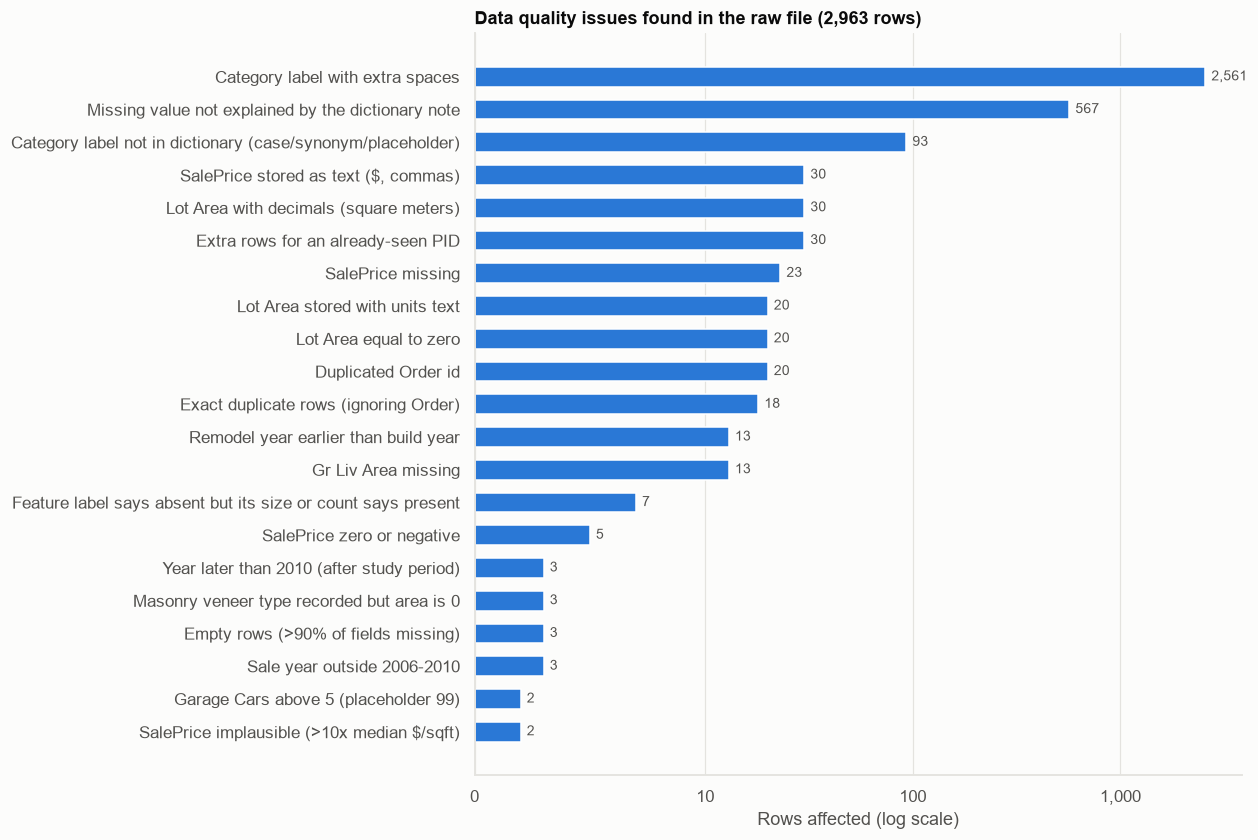

In [7]:
issues = audit_raw[audit_raw > 0].sort_values()
fig, ax = plt.subplots(figsize=(9, 0.36 * len(issues) + 1.2))
ax.barh(issues.index, issues.values, color=COLORS["blue"], height=0.6)
for y, v in enumerate(issues.values):
    ax.annotate(f"{v:,}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=COLORS["text2"])
ax.set_xscale("symlog", linthresh=10)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Rows affected (log scale)")
ax.set_title(f"Data quality issues found in the raw file ({len(raw):,} rows)")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_raw_data_quality_issues")
plt.show()

The structural missing values (no pool, no garage, and so on) are **not** counted as issues. The dictionary defines them as "the feature does not exist", and step 9 encodes them explicitly.

### 1.3 Repair pipeline

Each step works on a copy of the raw data and appends one or more entries to `QUALITY_LOG`: the issue, the rows affected, the action taken and the rationale.

In [8]:
QUALITY_LOG = []


def log(step, issue, rows, action, rationale):
    QUALITY_LOG.append({"step": step, "issue": issue, "rows_affected": int(rows),
                        "action": action, "rationale": rationale})


df = raw.copy()

**Step 1: Empty rows.** A few rows (count printed below) have no PID, no price and almost every field blank. They carry no information.

In [9]:
empty = df.isna().mean(axis=1) > 0.9
log(1, "Empty rows", empty.sum(), "Dropped", "No PID, no price, >90% of fields blank")
df = df.loc[~empty].copy()
print(f"Dropped {empty.sum()} empty rows -> {len(df):,} rows")

Dropped 3 empty rows -> 2,960 rows


**Step 2: Numbers stored as text, and wrong units.**
- `SalePrice` sometimes appears as `"$215,000"`. We strip the symbols; the value itself is correct.
- `Lot Area` sometimes appears as `"5362 sqft"`. We strip the units text.
- Some `Lot Area` values are written with a decimal point (e.g. `713.2`) while every other lot area is a whole number. These values are about ten times smaller than typical lots in their neighborhood, and the same sale sometimes appears a second time with its lot area in square feet. Both checks are printed below. The values were recorded in **square meters**, so we convert them (1 m² = 10.764 sqft).
- `Lot Area = 0` is physically impossible. We set it to missing for the imputer.

In [10]:
SQM_TO_SQFT = 10.7639

# SalePrice: remove "$" and thousands separators
price_txt = df["SalePrice"].astype("string")
has_symbols = price_txt.str.contains(r"[$,]", na=False)
df["SalePrice"] = pd.to_numeric(price_txt.str.replace(r"[$,\s]", "", regex=True), errors="coerce")
log(2, "SalePrice stored as text", has_symbols.sum(), "Removed '$' and ',' and converted to number",
    "Formatting problem only; the amount is valid")

# Lot Area: units text, square meters, zeros
lot_txt = df["Lot Area"].astype("string").str.strip()
has_units = lot_txt.str.contains(r"[A-Za-z]", na=False)
in_sqm = lot_txt.str.contains(r"\.", na=False)
lot = pd.to_numeric(lot_txt.str.replace(r"[^\d.]", "", regex=True), errors="coerce")
lot_before_conversion = lot.copy()
lot = lot.where(~in_sqm, (lot * SQM_TO_SQFT).round())
zero_lot = lot == 0
df["Lot Area"] = lot.mask(zero_lot)
log(2, "Lot Area with units text ('sqft')", has_units.sum(), "Removed text, kept the number",
    "Formatting problem only")
log(2, "Lot Area recorded in square meters", in_sqm.sum(), "Multiplied by 10.764 and rounded",
    "Only decimal values in a whole-number column, ~10x below typical lots, confirmed by a duplicate record")
log(2, "Lot Area equal to zero", zero_lot.sum(), "Set to missing (imputed later in the pipeline)",
    "A lot cannot have zero area")

# Identifier-like numeric codes read as floats -> integers
df["PID"] = df["PID"].astype("Int64")
df["MS SubClass"] = df["MS SubClass"].astype("Int64")

In [11]:
# Evidence for the square-meter conversion: corrupted values vs. their neighborhood's typical lot
nbhd_median_lot = lot.where(~in_sqm).groupby(df["Neighborhood"]).median()
sqm_evidence = pd.DataFrame({
    "PID": df.loc[in_sqm, "PID"],
    "Neighborhood": df.loc[in_sqm, "Neighborhood"],
    "value as recorded": lot_before_conversion[in_sqm],
    "converted to sqft": lot[in_sqm],
    "neighborhood median (sqft)": df.loc[in_sqm, "Neighborhood"].map(nbhd_median_lot),
})
sqm_evidence["recorded / median"] = (sqm_evidence["value as recorded"] / sqm_evidence["neighborhood median (sqft)"]).round(2)
sqm_evidence["converted / median"] = (sqm_evidence["converted to sqft"] / sqm_evidence["neighborhood median (sqft)"]).round(2)
print("Median ratio to the neighborhood's typical lot -> as recorded: "
      f"{sqm_evidence['recorded / median'].median():.2f} | after conversion: {sqm_evidence['converted / median'].median():.2f}")
# The same sale recorded a second time in square feet confirms the unit
raw_lot_txt = raw["Lot Area"].astype("string")
twins = raw.loc[raw["PID"].isin(df.loc[in_sqm, "PID"].astype(float)) & ~raw_lot_txt.str.contains(r"\.", na=False),
                ["PID", "Lot Area"]]
for pid, sqft_text in twins.itertuples(index=False):
    sqm = lot_before_conversion[in_sqm & df["PID"].eq(int(pid))].iloc[0]
    print(f"PID {int(pid)}: {sqm} in one record, {sqft_text} in its duplicate -> "
          f"{sqm} x {SQM_TO_SQFT} = {sqm * SQM_TO_SQFT:,.0f} sqft")
sqm_evidence.head(10)

Median ratio to the neighborhood's typical lot -> as recorded: 0.10 | after conversion: 1.02
PID 535305160: 713.2 in one record, 7677 in its duplicate -> 713.2 x 10.7639 = 7,677 sqft


,PID,Neighborhood,value as recorded,converted to sqft,neighborhood median (sqft),recorded / median,converted / median
27,533350120,Veenker,1512.4,16279.0,13165.0,0.11,1.24
45,907192030,CollgCr,830.1,8935.0,9675.0,0.09,0.92
82,905107240,Sawyer,960.1,10334.0,9402.0,0.1,1.1
246,905300020,Sawyer,947.6,10200.0,9402.0,0.1,1.08
427,527402380,NAmes,868.9,9353.0,9486.0,0.09,0.99
460,528427020,Somerst,893.0,9612.0,8125.0,0.11,1.18
483,923277030,Mitchel,613.1,6599.0,10172.0,0.06,0.65
639,902406020,OldTown,905.8,9750.0,7830.0,0.12,1.25
664,535305160,NAmes,713.2,7677.0,9486.0,0.08,0.81
747,534251320,NWAmes,909.5,9790.0,10944.0,0.08,0.89


**Step 3: Category labels.** Labels are matched to the dictionary codes after removing surrounding spaces and ignoring case (`rl`, `Rl`, ` RL` → `RL`). Two synonyms not in the dictionary are mapped explicitly: `paved` → `Pave` and `yes` → `Y`. Placeholders that mean "unknown" (`NA`, `N/A`, `??`, `unknown`) become missing; step 8 recovers them. The cell **asserts** that nothing else is left unmatched, so no label is dropped silently.

In [12]:
SYNONYMS = {"Street": {"paved": "Pave"}, "Central Air": {"yes": "Y"}}
PLACEHOLDERS = {"na", "n/a", "??", "unknown"}

changes = []
for col in CODED_TEXT_COLS:
    original = df[col].astype("string")
    lookup = {code.lower(): code for code in VALID_CODES[col]} | SYNONYMS.get(col, {})
    key = original.str.strip().str.lower()
    mapped = key.map(lookup)
    unmatched = original.notna() & mapped.isna()
    assert key[unmatched].isin(PLACEHOLDERS).all(), f"{col}: unexpected labels {set(original[unmatched])}"
    changed = original.notna() & (original != mapped).fillna(True)
    if changed.any():
        changes.append(pd.DataFrame({"column": col, "original": original[changed],
                                     "cleaned": mapped[changed].fillna("<missing>")}))
    df[col] = mapped.astype(object).where(mapped.notna(), np.nan)

label_changes = pd.concat(changes)
summary = (label_changes.assign(original=label_changes["original"].map(repr))
           .groupby(["column", "original", "cleaned"]).size().rename("rows").reset_index())
log(3, "Category labels with extra spaces / wrong case / synonyms", label_changes.index.nunique(),
    "Mapped to the dictionary code", "Same category written differently; would otherwise split one category into several")
summary

,column,original,cleaned,rows
0,Central Air,'YES',Y,8
1,Central Air,'Yes',Y,8
2,Central Air,'y',Y,7
3,Central Air,'yes',Y,8
4,MS Zoning,' RL',RL,10
5,MS Zoning,'RL ',RL,10
6,MS Zoning,'Rl',RL,10
7,MS Zoning,'rl',RL,10
8,Neighborhood,'??',<missing>,4
9,Neighborhood,'N/A',<missing>,4


**Step 4: Duplicates.** Once formats are normalized (step 2), more rows become exact copies: `"$330,000"` and `330000` now match. Exact copies are dropped first. Then we look at PIDs that still appear more than once. A PID identifies a property, and a property could legitimately sell twice, so we check whether the repeated rows describe the **same sale** (same month and year).

In [13]:
exact_dup = df.drop(columns="Order").duplicated()
log(4, "Exact duplicate rows", exact_dup.sum(), "Dropped (kept first)", "Same sale recorded twice")
df = df.loc[~exact_dup].copy()

repeated = df[df["PID"].duplicated(keep=False)].sort_values(["PID", "Order"])
same_sale = repeated.groupby("PID")[["Yr Sold", "Mo Sold"]].nunique().max(axis=1).eq(1)
print(f"PIDs still repeated: {repeated['PID'].nunique()} | all repeats share the same sale month: {same_sale.all()}")


def describe_differences(group):
    cols = [c for c in group.columns.drop("Order") if group[c].astype("string").nunique(dropna=False) > 1]
    return "; ".join(f"{c}: " + " vs ".join(group[c].astype("string").fillna("NaN")) for c in cols)


near_dup_table = repeated.groupby("PID").apply(describe_differences, include_groups=False).rename("differences").to_frame()
spread = repeated.groupby("PID").agg(price=("SalePrice", lambda s: (s.max() - s.min()) / s.max()),
                                     lot=("Lot Area", lambda s: s.max() - s.min()))
print(f"Largest difference between copies of the same sale: price {spread['price'].max():.2%}, "
      f"lot area {spread['lot'].max():.0f} sqft")
near_dup_table

PIDs still repeated: 11 | all repeats share the same sale month: True
Largest difference between copies of the same sale: price 0.22%, lot area 1 sqft


,differences
PID,
531367010,Lot Area: 11024.0 vs 11023.0; SalePrice: 18680...
533208020,Garage Yr Blt: 2006.0 vs 1987.0
533213120,Lot Area: 2281.0 vs 2280.0; SalePrice: 173000 ...
533221040,Lot Area: 2999.0 vs 2998.0; SalePrice: 180100 ...
535353060,Lot Area: 9532.0 vs 9533.0; SalePrice: 102800 ...
902205010,Lot Area: 5926.0 vs 5925.0; SalePrice: 45100 v...
903231090,Lot Area: 6240.0 vs 6239.0; SalePrice: 126000 ...
903454100,Lot Area: 6875.0 vs 6876.0; SalePrice: 140900 ...
907202160,Lot Area: 10971.0 vs 10970.0; SalePrice: NaN v...


Every repeated PID is the same sale recorded twice (same sale month). The copies differ only slightly, or by a missing value in one copy: the largest differences are printed above, far too small to change any conclusion. We keep **one record per sale**: the copy with a valid price and the fewest missing values, and on a tie the lowest `Order` (the first recorded).

In [14]:
ranked = (df.assign(_price_ok=df["SalePrice"].gt(0), _n_missing=df.isna().sum(axis=1))
            .sort_values(["PID", "_price_ok", "_n_missing", "Order"], ascending=[True, False, True, True]))
keep = ranked.drop_duplicates("PID").index
n_near = len(df) - len(keep)
log(4, "Same sale recorded twice with small differences (same PID & sale month)", n_near,
    "Kept one record: valid price, fewest missing values, then first Order",
    "Differences <0.1% (about $100 / 1 sqft), so the choice does not affect results")
df = df.loc[df.index.isin(keep)].copy()
assert df["PID"].is_unique and df["Order"].is_unique
print(f"Removed {exact_dup.sum()} exact + {n_near} near duplicates -> {len(df):,} rows; PID and Order are now unique")

Removed 19 exact + 11 near duplicates -> 2,930 rows; PID and Order are now unique


**Step 5: Rebuild missing `Gr Liv Area`.** Above-ground living area is, by definition, 1st floor + 2nd floor + low-quality finished area. The cell below confirms the identity holds in every row where all four values are present, so the missing values can be computed rather than guessed.

In [15]:
components = df["1st Flr SF"] + df["2nd Flr SF"] + df["Low Qual Fin SF"]
mismatch = ((components - df["Gr Liv Area"]).abs() > 1).sum()
rebuild = df["Gr Liv Area"].isna() & components.notna()
df.loc[rebuild, "Gr Liv Area"] = components[rebuild]
log(5, "Gr Liv Area missing", rebuild.sum(), "Computed as 1st + 2nd + low-quality floor area",
    "Exact identity, verified with 0 mismatches in complete rows")
print(f"Rows where Gr Liv Area differs from the sum of its parts: {mismatch} | "
      f"rebuilt {rebuild.sum()} values; still missing: {df['Gr Liv Area'].isna().sum()}")

Rows where Gr Liv Area differs from the sum of its parts: 0 | rebuilt 10 values; still missing: 0

**Step 6: Invalid sale prices (agreed: drop).** The sale price is what the models learn from, so we do not invent it. There are three kinds of invalid price:
- **missing**;
- **zero or negative**: plausible amounts with a flipped sign, but we cannot verify that;
- **implausible**: price per sqft (`price_per_sqft`) above 10× the median. The table below shows these are placeholder-looking values on ordinary houses.

In [16]:
price_per_sqft = df["SalePrice"] / df["Gr Liv Area"]
target_issue = pd.Series(pd.NA, index=df.index, dtype="string")
target_issue[df["SalePrice"].isna()] = "missing"
target_issue[df["SalePrice"] <= 0] = "zero or negative"
target_issue[price_per_sqft > 10 * price_per_sqft.median()] = "implausible (>10x median $/sqft)"
bad_target = target_issue.notna()

display(df.loc[bad_target & target_issue.ne("missing"),
               ["PID", "Neighborhood", "Gr Liv Area", "Overall Qual", "SalePrice"]]
        .assign(price_per_sqft=price_per_sqft.round(0), issue=target_issue))
print(f"Median $/sqft of valid sales: {price_per_sqft[~bad_target].median():.0f}")
for kind, n in target_issue.value_counts().items():
    log(6, f"SalePrice {kind}", n, "Dropped", "The target is never invented; see the agreed decision")
df = df.loc[~bad_target].copy()
print(f"Dropped {bad_target.sum()} rows with an invalid price -> {len(df):,} rows")

,PID,Neighborhood,Gr Liv Area,Overall Qual,SalePrice,price_per_sqft,issue
300,914476520,Mitchel,1560.0,7.0,12500000,8013.0,implausible (>10x median $/sqft)
660,907135180,CollgCr,990.0,4.0,-129000,-130.0,zero or negative
1360,911204100,IDOTRR,952.0,4.0,9999999,10504.0,implausible (>10x median $/sqft)
1629,903427090,OldTown,1666.0,8.0,-62500,-38.0,zero or negative
1710,910200080,IDOTRR,919.0,6.0,-105000,-114.0,zero or negative
2289,527450460,BrDale,1030.0,6.0,-167900,-163.0,zero or negative
2361,908128100,Edwards,1724.0,7.0,-138400,-80.0,zero or negative


Median $/sqft of valid sales: 120
Dropped 26 rows with an invalid price -> 2,904 rows


**Step 7: Impossible years (agreed: rule-based repair using evidence in the same row).**
- **Sale year outside 2006–2010.** The rows dated before 2006 (table below) are new homes built after their recorded sale year, so they would be "sold before being built", and they fall outside the period the dictionary describes. The true year cannot be recovered, so the rows are dropped.
- **Build year after 2010.** Replaced with the garage year when that is plausible, otherwise the remodel year.
- **Garage year after 2010.** Replaced with the house's build year.
- **Build year missing.** Filled with the earlier of the garage year and the remodel year: a house cannot be remodeled before it is built, and it is usually built no later than its garage. The cell tests this rule on houses where all three years are known, and compares it with a median imputer.
- **Remodel year earlier than build year.** The dictionary says *remodel = build year when there was no remodel*, so remodel is set to the build year ("not remodeled").

New homes whose build or remodel year is one year *after* the sale year are **kept**: these are sales of homes still under construction (`Sale Condition = Partial`).

In [17]:
year_cols = ["Year Built", "Year Remod/Add", "Garage Yr Blt", "Yr Sold", "Sale Condition"]

bad_sale_year = ~df["Yr Sold"].between(2006, 2010)
display(df.loc[bad_sale_year, year_cols])
log(7, "Sale year outside 2006-2010", bad_sale_year.sum(), "Dropped",
    "New homes 'sold before being built' and outside the documented period; true year unrecoverable")
df = df.loc[~bad_sale_year].copy()

bad_built = df["Year Built"] > 2010
before = df.loc[bad_built, year_cols].copy()
garage_ok = df["Garage Yr Blt"].between(1800, 2010)
df.loc[bad_built, "Year Built"] = np.where(garage_ok[bad_built], df.loc[bad_built, "Garage Yr Blt"],
                                           df.loc[bad_built, "Year Remod/Add"])
log(7, "Build year after 2010", bad_built.sum(), "Replaced with garage year (or remodel year)",
    "Same-row evidence: garage and remodel years agree with each other")

bad_garage = df["Garage Yr Blt"] > 2010
before = pd.concat([before, df.loc[bad_garage, year_cols]])
df.loc[bad_garage, "Garage Yr Blt"] = df.loc[bad_garage, "Year Built"]
log(7, "Garage year after 2010", bad_garage.sum(), "Replaced with build year",
    "Garage built with the house (new home); 2207 is a typo")

remod_before_built = df["Year Remod/Add"] < df["Year Built"]
df.loc[remod_before_built, "Year Remod/Add"] = df.loc[remod_before_built, "Year Built"]
log(7, "Remodel year earlier than build year", remod_before_built.sum(), "Set remodel year = build year",
    "Dictionary rule: equal to build year when there was no remodel")

# Missing build year: earlier of garage year and remodel year, tested where all three years are known
known_years = df[["Year Built", "Garage Yr Blt", "Year Remod/Add"]].dropna()
rule_estimate = known_years[["Garage Yr Blt", "Year Remod/Add"]].min(axis=1)
rule_exact = (rule_estimate == known_years["Year Built"]).mean()
rule_mae = (rule_estimate - known_years["Year Built"]).abs().mean()
median_mae = (known_years["Year Built"].median() - known_years["Year Built"]).abs().mean()
missing_built = df["Year Built"].isna() & df[["Garage Yr Blt", "Year Remod/Add"]].notna().any(axis=1)
df.loc[missing_built, "Year Built"] = df.loc[missing_built, ["Garage Yr Blt", "Year Remod/Add"]].min(axis=1)
log(7, "Build year missing", missing_built.sum(), "Filled with the earlier of garage year and remodel year",
    "Same-row evidence; tested on houses where all three years are known (see Key results)")

print("Rows with an impossible build/garage year - before and after:")
display(before.join(df[["Year Built", "Garage Yr Blt"]].add_suffix(" (repaired)")))
built_after_sale = df["Year Built"] > df["Yr Sold"]
assert df.loc[built_after_sale, "Sale Condition"].eq("Partial").all()   # all are sales of homes under construction
print(f"Remodel years corrected: {remod_before_built.sum()} | "
      f"homes built after the sale year (kept, all 'Partial' = under construction): {built_after_sale.sum()}")
print(f"Build year filled for {missing_built.sum()} houses. Rule check on {len(known_years):,} houses with all three "
      f"years: exact for {rule_exact:.1%}, mean error {rule_mae:.1f} years (median imputer: {median_mae:.1f} years)")


,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Sale Condition
629,2006.0,2006.0,2006.0,2005.0,Partial
1800,2006.0,2007.0,2006.0,2005.0,Partial
2181,2007.0,2008.0,2008.0,2005.0,Partial


Rows with an impossible build/garage year - before and after:


,Year Built,Year Remod/Add,Garage Yr Blt,Yr Sold,Sale Condition,Year Built (repaired),Garage Yr Blt (repaired)
510,2099.0,2006.0,2006.0,2007.0,Partial,2006.0,2006.0
1697,2050.0,1968.0,1968.0,2007.0,Normal,1968.0,1968.0
2864,2006.0,2007.0,2207.0,2007.0,Partial,2006.0,2006.0


Remodel years corrected: 11 | homes built after the sale year (kept, all 'Partial' = under construction): 3
Build year filled for 10 houses. Rule check on 2,733 houses with all three years: exact for 84.7%, mean error 3.8 years (median imputer: 24.5 years)


**Step 7b: Placeholder garage capacity.** `Garage Cars` (garage size in car capacity) holds the value 99 in a few rows. That is a placeholder, not a garage. The same row's `Garage Area` (garage size in sqft) shows the real size, so we replace 99 with the capacity whose typical (median) garage area is closest to it.

In [18]:
MAX_REAL_CAPACITY = 5   # the largest real garage in the data holds 5 cars; anything above is a placeholder
bad_capacity = df["Garage Cars"] > MAX_REAL_CAPACITY
valid_garage = df["Garage Cars"].between(1, MAX_REAL_CAPACITY) & df["Garage Area"].gt(0)
median_area = df.loc[valid_garage].groupby("Garage Cars")["Garage Area"].median()
repaired = df.loc[bad_capacity, "Garage Area"].apply(lambda area: (median_area - area).abs().idxmin())

print("Median garage area by capacity (sqft):", median_area.round(0).astype(int).to_dict())
display(pd.DataFrame({"Garage Area (sqft)": df.loc[bad_capacity, "Garage Area"],
                      "Garage Cars as recorded": df.loc[bad_capacity, "Garage Cars"],
                      "Garage Cars repaired": repaired}))
df.loc[bad_capacity, "Garage Cars"] = repaired
log("7b", "Garage Cars placeholder (99)", bad_capacity.sum(),
    "Replaced with the capacity whose median Garage Area is closest", "Same-row evidence: the garage's area shows its real size")

Median garage area by capacity (sqft): {1.0: 288, 2.0: 505, 3.0: 806, 4.0: 892, 5.0: 1184}


,Garage Area (sqft),Garage Cars as recorded,Garage Cars repaired
313,264.0,99.0,1.0
2349,336.0,99.0,1.0


**Step 8: Unknown location codes (agreed: nearest parcel ID).** A PID is a tax-map parcel number, so parcels with close numbers sit close together. Before using this, we **test it**: for every property with a known code, we hide the code and predict it from the nearest other PID (leave-one-out validation). A code is recovered this way only if that accuracy is at least `MIN_LOCATION_ACCURACY` (95%).
- `Neighborhood` (physical location within city limits): placeholders such as `NA` or `??`, set to missing in step 3.
- `MS Zoning` (general zoning classification): empty values. The dictionary note does not list this column, so its gaps are data quality issues. Zoning is tied to location, so the same method applies.

In [19]:
def nearest_pid_label(query, ref_pids, ref_labels):
    """Label of the reference parcel whose PID is numerically closest to each query PID."""
    order = np.argsort(ref_pids)
    p, lab = ref_pids[order], ref_labels[order]
    pos = np.searchsorted(p, query)
    left, right = np.clip(pos - 1, 0, len(p) - 1), np.clip(pos, 0, len(p) - 1)
    use_left = np.abs(query - p[left]) <= np.abs(p[right] - query)
    return np.where(use_left, lab[left], lab[right])


def nearest_pid_loo_accuracy(pids, labels):
    """Leave-one-out: predict each known label from its nearest *other* parcel."""
    order = np.argsort(pids)
    p, lab = pids[order], labels[order]
    d_prev, d_next = np.r_[np.inf, np.diff(p)], np.r_[np.diff(p), np.inf]
    prev_lab, next_lab = np.r_[lab[:1], lab[:-1]], np.r_[lab[1:], lab[-1:]]
    return (np.where(d_prev <= d_next, prev_lab, next_lab) == lab).mean()


MIN_LOCATION_ACCURACY = 0.95   # recover a code from the nearest parcel only if leave-one-out accuracy reaches this

known = df["Neighborhood"].notna()
ref_pids = df.loc[known, "PID"].to_numpy(dtype="int64")
ref_labels = df.loc[known, "Neighborhood"].to_numpy(dtype=object)
loo_acc = nearest_pid_loo_accuracy(ref_pids, ref_labels)
majority_acc = df.loc[known, "Neighborhood"].value_counts(normalize=True).iloc[0]
print(f"Leave-one-out accuracy, nearest PID: {loo_acc:.1%}  (baseline 'most common neighborhood': {majority_acc:.1%})")

assert loo_acc >= MIN_LOCATION_ACCURACY, "nearest-parcel recovery not accurate enough for Neighborhood"
unknown = ~known
df.loc[unknown, "Neighborhood"] = nearest_pid_label(df.loc[unknown, "PID"].to_numpy(dtype="int64"), ref_pids, ref_labels)
log(8, "Neighborhood unknown (NA, N/A, ??, unknown)", unknown.sum(), "Assigned the neighborhood of the nearest parcel ID",
    f"PIDs are spatial; validated at {loo_acc:.1%} leave-one-out accuracy")
display(df.loc[unknown, ["PID", "Neighborhood"]].value_counts("Neighborhood").rename("rows recovered").to_frame().T)

# MS Zoning: same method, same test
known_zone = df["MS Zoning"].notna()
zone_pids = df.loc[known_zone, "PID"].to_numpy(dtype="int64")
zone_labels = df.loc[known_zone, "MS Zoning"].to_numpy(dtype=object)
zone_acc = nearest_pid_loo_accuracy(zone_pids, zone_labels)
zone_majority = df.loc[known_zone, "MS Zoning"].value_counts(normalize=True).iloc[0]
print(f"MS Zoning, leave-one-out accuracy, nearest PID: {zone_acc:.1%}  (baseline 'most common zone': {zone_majority:.1%})")
missing_zone = ~known_zone
if zone_acc >= MIN_LOCATION_ACCURACY:
    df.loc[missing_zone, "MS Zoning"] = nearest_pid_label(df.loc[missing_zone, "PID"].to_numpy(dtype="int64"),
                                                          zone_pids, zone_labels)
    log(8, "MS Zoning missing", missing_zone.sum(), "Assigned the zoning of the nearest parcel ID",
        f"Zoning is tied to location; validated at {zone_acc:.1%} leave-one-out accuracy")
else:
    print("Accuracy below the threshold: MS Zoning gaps are left for the imputer")

Leave-one-out accuracy, nearest PID: 98.8%  (baseline 'most common neighborhood': 15.2%)


Neighborhood,NAmes,BrkSide,Sawyer,Edwards,Gilbert,Timber,IDOTRR,Blmngtn,OldTown,SawyerW,Crawfor
rows recovered,4,2,2,2,2,2,1,1,1,1,1


MS Zoning, leave-one-out accuracy, nearest PID: 98.9%  (baseline 'most common zone': 77.8%)


**Step 9: Features that do not exist.** The dictionary's note says that for pools, miscellaneous features, alleys, fences, fireplaces, masonry veneer, garages and basements, an empty value means "the house does not have it". We encode that explicitly as `"Absent"`, and set the matching areas and counts to 0, so these values are never mistaken for real gaps.
- **Garage and basement fields:** the note applies when the whole feature is absent (`Garage Type` or `Bsmt Qual` empty). A missing garage *finish* on a house that *has* a garage is a real gap, left for the imputer. `Garage Yr Blt` stays empty when there is no garage, because no year applies.
- **Masonry veneer:** an empty `Mas Vnr Type` (masonry veneer type) means no veneer, so an empty or zero `Mas Vnr Area` (veneer area, sqft) becomes 0. When the type is empty but the area is above 0, the row contradicts the note: the area shows a veneer exists. The type is set to `"Unknown"` and the area is kept. When a type is recorded but the area is 0, the data does not show which field is wrong, so the row is kept as recorded and reported by the audit.

In [20]:
STRUCTURAL = {
    # group: (rows where the feature is absent, text columns -> "Absent", numeric columns -> 0)
    "basement": (df["Bsmt Qual"].isna() & df["Total Bsmt SF"].fillna(0).eq(0),
                 ["Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"],
                 ["BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath"]),
    "garage": (df["Garage Type"].isna() & df["Garage Area"].fillna(0).eq(0),
               ["Garage Type", "Garage Finish", "Garage Qual", "Garage Cond"], ["Garage Cars", "Garage Area"]),
    "fireplace": (df["Fireplace Qu"].isna() & df["Fireplaces"].eq(0), ["Fireplace Qu"], []),
    "pool": (df["Pool QC"].isna() & df["Pool Area"].eq(0), ["Pool QC"], []),
    "masonry veneer": (df["Mas Vnr Type"].isna() & ~df["Mas Vnr Area"].gt(0), ["Mas Vnr Type"], ["Mas Vnr Area"]),
    "alley": (df["Alley"].isna(), ["Alley"], []),
    "fence": (df["Fence"].isna(), ["Fence"], []),
    "misc feature": (df["Misc Feature"].isna() & df["Misc Val"].eq(0), ["Misc Feature"], []),
}
for group, (absent, text_cols, num_cols) in STRUCTURAL.items():
    for c in text_cols:
        df.loc[absent & df[c].isna(), c] = ABSENT
    for c in num_cols:
        df.loc[absent & df[c].isna(), c] = 0
    log(9, f"No {group} (NaN by design)", absent.sum(), f"Encoded as '{ABSENT}' (areas/counts = 0)",
        "Dictionary: NaN means the feature does not exist")
print({g: int(m.sum()) for g, (m, _, _) in STRUCTURAL.items()})

# Masonry veneer contradictions (dictionary note: an empty type means no veneer)
veneer_type_unknown = df["Mas Vnr Type"].isna() & df["Mas Vnr Area"].gt(0)
df.loc[veneer_type_unknown, "Mas Vnr Type"] = UNKNOWN
log(9, "Masonry veneer: type empty but area above 0", veneer_type_unknown.sum(),
    f"Type set to '{UNKNOWN}', area kept", "Contradicts the dictionary note; the area shows a veneer exists")
type_without_area = df["Mas Vnr Type"].notna() & ~df["Mas Vnr Type"].isin([ABSENT, UNKNOWN]) & df["Mas Vnr Area"].eq(0)
log(9, "Masonry veneer: type recorded but area is 0", type_without_area.sum(), "Kept as recorded",
    "The data does not show which of the two fields is wrong")
print(f"Masonry veneer: type set to '{UNKNOWN}' for {veneer_type_unknown.sum()} rows; "
      f"type recorded with zero area (kept as recorded): {type_without_area.sum()} rows")

{'basement': 79, 'garage': 156, 'fireplace': 1407, 'pool': 2888, 'masonry veneer': 1754, 'alley': 2706, 'fence': 2333, 'misc feature': 2796}
Masonry veneer: type set to 'Unknown' for 7 rows; type recorded with zero area (kept as recorded): 3 rows


### 1.4 Verification: re-run the audit on the cleaned data

Every check must reach zero after cleaning, except two that remain **by design**: real gaps that are investigated in 1.7 and filled by the imputer inside the model pipeline, and a masonry inconsistency kept as recorded (step 9). The table states the reason next to each.

In [21]:
audit_clean = audit(df)
REMAIN_BY_DESIGN = {
    "Missing value not explained by the dictionary note":
        "real gaps: Lot Frontage (dropped in 1.6) and the gaps investigated in 1.7, filled by the imputer",
    "Masonry veneer type recorded but area is 0": "kept as recorded: the data does not show which field is wrong",
}
must_be_zero = audit_clean.drop(list(REMAIN_BY_DESIGN))
assert must_be_zero.eq(0).all(), must_be_zero[must_be_zero > 0]

audit_compare = pd.DataFrame({"raw": audit_raw, "cleaned": audit_clean})
audit_compare["after cleaning"] = [
    "remains by design: " + REMAIN_BY_DESIGN[check] if check in REMAIN_BY_DESIGN else "none left"
    for check in audit_compare.index]
print(f"Rows: {len(raw):,} raw -> {len(df):,} cleaned ({len(raw) - len(df)} removed). "
      f"All {len(must_be_zero)} checks that must reach zero do; {len(REMAIN_BY_DESIGN)} remain by design.")
unexplained_rows = unexplained_missing(df)
print(f"Sales with a gap the dictionary note does not explain: {unexplained_rows.any(axis=1).sum():,}; "
      f"excluding Lot Frontage (dropped in 1.6): {unexplained_rows.drop(columns='Lot Frontage').any(axis=1).sum():,}")
with pd.option_context("display.max_colwidth", None):
    display(audit_compare)

Rows: 2,963 raw -> 2,901 cleaned (62 removed). All 20 checks that must reach zero do; 2 remain by design.


Sales with a gap the dictionary note does not explain: 524; excluding Lot Frontage (dropped in 1.6): 42


,raw,cleaned,after cleaning
Empty rows (>90% of fields missing),3,0,none left
Exact duplicate rows (ignoring Order),18,0,none left
Extra rows for an already-seen PID,30,0,none left
Duplicated Order id,20,0,none left
"SalePrice stored as text ($, commas)",30,0,none left
SalePrice missing,23,0,none left
SalePrice zero or negative,5,0,none left
SalePrice implausible (>10x median $/sqft),2,0,none left
Lot Area stored with units text,20,0,none left
Lot Area with decimals (square meters),30,0,none left


In [22]:
df.to_csv(PROCESSED_DIR / "clean_all_sales.csv", index=False)
print(f"Saved {len(df):,} valid sales to {(PROCESSED_DIR / 'clean_all_sales.csv').relative_to(ROOT)}")

Saved 2,901 valid sales to data\processed\clean_all_sales.csv

### 1.5 Analysis sample: which sales the price models learn from

**Agreed decision:** model **Normal** and **Partial** (new home) sales, with an `is_new_home` flag, and exclude houses above 4,000 sqft. Q3 will be re-checked on Normal sales only. The evidence follows.

**a) Non-market sales sell at a discount.** We fit a simple reference model on Normal sales only (log price ~ log living area + overall quality + build year). We then compare each sale type with the price that model expects for a comparable house. The 95% intervals come from a bootstrap of the median gap (using `rng_for`, so they are reproducible).

In [23]:
ref = df.dropna(subset=["Gr Liv Area", "Overall Qual", "Year Built"]).copy()
X_ref = sm.add_constant(np.column_stack([np.log(ref["Gr Liv Area"]), ref["Overall Qual"], ref["Year Built"]]))
y_ref = np.log(ref["SalePrice"].to_numpy())
is_normal = ref["Sale Condition"].eq("Normal").to_numpy()
ref_fit = sm.OLS(y_ref[is_normal], X_ref[is_normal]).fit()
ref["gap_vs_normal_sale"] = y_ref - ref_fit.predict(X_ref)


def bootstrap_median(x, rng, n_boot=2000):
    x = np.asarray(x)
    meds = np.median(x[rng.integers(0, len(x), size=(n_boot, len(x)))], axis=1)
    return np.percentile(meds, [2.5, 97.5])


rows = []
for cond, g in ref.groupby("Sale Condition"):
    lo, hi = bootstrap_median(g["gap_vs_normal_sale"], rng_for(f"1.5 sale condition bootstrap: {cond}"))
    rows.append({"Sale Condition": cond, "n": len(g), "median price": g["SalePrice"].median(),
                 "median $/sqft": (g["SalePrice"] / g["Gr Liv Area"]).median(),
                 "% vs comparable Normal sale": 100 * np.expm1(g["gap_vs_normal_sale"].median()),
                 "95% CI low": 100 * np.expm1(lo), "95% CI high": 100 * np.expm1(hi)})
cond_effect = pd.DataFrame(rows).set_index("Sale Condition").sort_values("% vs comparable Normal sale")
print(f"Reference model on Normal sales: R² = {ref_fit.rsquared:.3f}")
cond_effect.round(1)

Reference model on Normal sales: R² = 0.815

,n,median price,median $/sqft,% vs comparable Normal sale,95% CI low,95% CI high
Sale Condition,,,,,,
AdjLand,12,110000.0,83.8,-11.1,-26.6,-1.6
Abnorml,189,129000.0,100.7,-8.2,-11.2,-5.0
Family,44,144900.0,109.9,-4.6,-11.1,2.1
Normal,2392,158750.0,119.3,0.5,-0.1,1.2
Partial,241,250000.0,149.0,4.2,1.2,6.9
Alloca,23,150909.0,86.6,4.7,-21.8,7.3


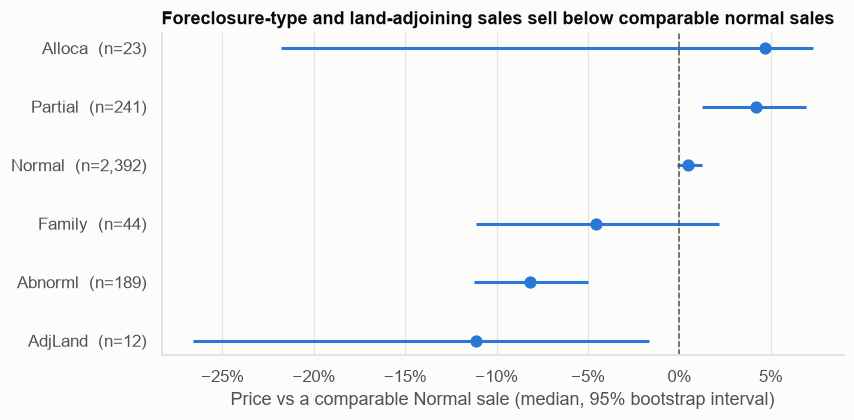

In [24]:
t = cond_effect.sort_values("% vs comparable Normal sale")
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(t))
ax.errorbar(t["% vs comparable Normal sale"], y,
            xerr=[t["% vs comparable Normal sale"] - t["95% CI low"], t["95% CI high"] - t["% vs comparable Normal sale"]],
            fmt="o", color=COLORS["blue"], ecolor=COLORS["blue"], elinewidth=2, markersize=7, capsize=0)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
ax.set_yticks(y, labels=[f"{c}  (n={n:,})" for c, n in zip(t.index, t["n"])])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Price vs a comparable Normal sale (median, 95% bootstrap interval)")
ax.set_title("Foreclosure-type and land-adjoining sales sell below comparable normal sales")
ax.grid(axis="y", visible=False)
save_fig(fig, "01_sale_condition_discount")
plt.show()

**b) Houses above 4,000 sqft.** These are rare (counts printed below). The dataset's author recommends removing all houses above 4,000 sqft. The table compares each market sale above that size with a reference model fitted *without* them. The new homes in Edwards sold for a fraction of what their size and quality imply, which points to incomplete transactions. The NoRidge sale is a genuine luxury home with no comparable houses to learn from.

In [25]:
market = df["Sale Condition"].isin(["Normal", "Partial"])
large = df["Gr Liv Area"] > 4000
fit_data = ref.loc[ref.index.isin(df.index[market & ~large])]
X_fit = sm.add_constant(np.column_stack([np.log(fit_data["Gr Liv Area"]), fit_data["Overall Qual"], fit_data["Year Built"]]))
fit_no_large = sm.OLS(np.log(fit_data["SalePrice"]), X_fit).fit()

big = df.loc[large & market]
X_big = sm.add_constant(np.column_stack([np.log(big["Gr Liv Area"]), big["Overall Qual"], big["Year Built"]]), has_constant="add")
outlier_table = big[["Neighborhood", "Gr Liv Area", "Overall Qual", "Sale Condition", "SalePrice"]].assign(
    expected_price=np.exp(fit_no_large.predict(X_big)).round(-3))
outlier_table["actual vs expected"] = (outlier_table["SalePrice"] / outlier_table["expected_price"] - 1).map("{:+.0%}".format)
print(f"Houses above 4,000 sqft: {large.sum()} among valid sales, {(large & market).sum()} of them market sales (listed below) | "
      f"houses above 3,000 sqft: {(df['Gr Liv Area'] > 3000).sum()}")
outlier_table

Houses above 4,000 sqft: 5 among valid sales, 4 of them market sales (listed below) | houses above 3,000 sqft: 25


,Neighborhood,Gr Liv Area,Overall Qual,Sale Condition,SalePrice,expected_price,actual vs expected
499,Edwards,5642.0,10.0,Partial,160000,621000.0,-74%
618,Edwards,4676.0,10.0,Partial,184750,562000.0,-67%
2276,Edwards,5095.0,10.0,Partial,183850,589000.0,-69%
2319,NoRidge,4316.0,10.0,Normal,755000,518000.0,+46%


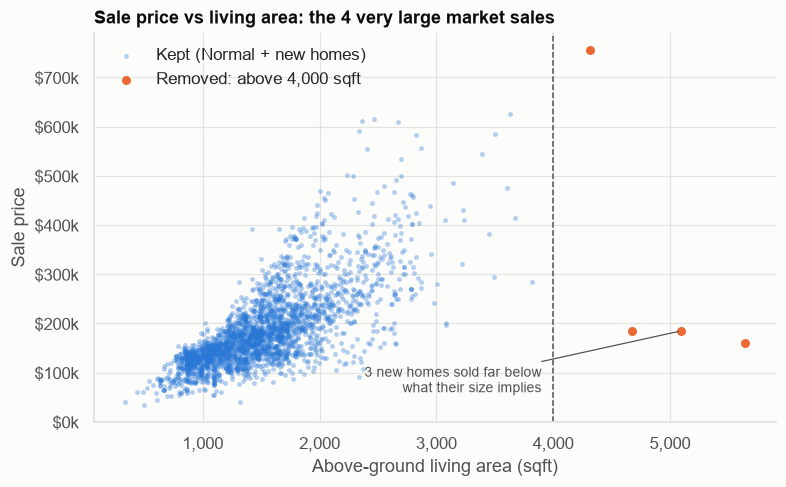

In [26]:
plot_df = df.loc[market]
fig, ax = plt.subplots(figsize=(8, 4.6))
kept = plot_df["Gr Liv Area"] <= 4000
ax.scatter(plot_df.loc[kept, "Gr Liv Area"], plot_df.loc[kept, "SalePrice"], s=10, alpha=0.35,
           color=COLORS["blue"], linewidths=0, label="Kept (Normal + new homes)")
ax.scatter(plot_df.loc[~kept, "Gr Liv Area"], plot_df.loc[~kept, "SalePrice"], s=55,
           color=COLORS["orange"], edgecolor=COLORS["surface"], linewidth=1.5, label="Removed: above 4,000 sqft")
ax.axvline(4000, color=COLORS["text2"], lw=1, ls="--")
ax.annotate("3 new homes sold far below\nwhat their size implies", xy=(5100, 185000), xytext=(3900, 60000),
            fontsize=9, color=COLORS["text2"], ha="right", arrowprops=dict(arrowstyle="-", color=COLORS["text2"], lw=0.8))
ax.yaxis.set_major_formatter(USD)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Above-ground living area (sqft)")
ax.set_ylabel("Sale price")
ax.set_title("Sale price vs living area: the 4 very large market sales")
ax.legend(frameon=False, loc="upper left")
save_fig(fig, "01_large_house_outliers")
plt.show()

In [27]:
sample = df.loc[market & ~large].copy()
# New variable (see "Variables used in this section"): flags new construction so its premium is modeled separately
sample["is_new_home"] = sample["Sale Condition"].eq("Partial").astype(int)
log("1.5", "Non-market sales (Abnorml, Family, Alloca, AdjLand)", (~market).sum(), "Excluded from the analysis sample",
    "Not open-market prices (e.g. foreclosure-type sales ~8% below comparable Normal sales)")
log("1.5", "Houses above 4,000 sqft", (market & large).sum(), "Excluded from the analysis sample",
    "3 incomplete-looking new-home sales, 1 luxury home with no comparables; model valid up to 4,000 sqft")
print(f"Analysis sample: {len(sample):,} sales ({sample['is_new_home'].sum()} new homes, "
      f"{(1 - sample['is_new_home']).sum():,} normal resales)")

Analysis sample: 2,629 sales (238 new homes, 2,391 normal resales)


### 1.6 Lot Frontage: dropped (team decision)

`Lot Frontage` is the linear feet of street connected to the property. The team decided to drop it after reviewing the evidence below and the cross-validation check in Section 2.4 (model error with and without it).
- **What we give up:** the analysis says nothing about street frontage itself. The lot is still described by `Lot Area` (lot size) and `Lot Config` (inside, corner, cul-de-sac...).
- **Alternative considered:** fill it with the neighborhood median plus a "was missing" flag.

Evidence on the analysis sample:

In [28]:
lf_data = sample.dropna(subset=["Lot Frontage", "Lot Area", "Year Built"])
X_lf = sm.add_constant(np.column_stack([np.log(lf_data["Gr Liv Area"]), lf_data["Overall Qual"],
                                        lf_data["Year Built"], np.log(lf_data["Lot Area"])]))
resid_lf = sm.OLS(np.log(lf_data["SalePrice"]), X_lf).fit().resid
lf_evidence = pd.Series({
    "share missing": sample["Lot Frontage"].isna().mean(),
    "Spearman: Lot Frontage vs price": sample["Lot Frontage"].corr(sample["SalePrice"], method="spearman"),
    "Spearman: Lot Area vs price": sample["Lot Area"].corr(sample["SalePrice"], method="spearman"),
    "Spearman: Lot Frontage vs Lot Area": sample["Lot Frontage"].corr(sample["Lot Area"], method="spearman"),
    "Spearman: Lot Frontage vs price left unexplained by size, quality, age and lot area":
        lf_data["Lot Frontage"].corr(resid_lf, method="spearman"),
}).round(3)
lf_evidence.to_frame("value")

,value
share missing,0.172
Spearman: Lot Frontage vs price,0.416
Spearman: Lot Area vs price,0.438
Spearman: Lot Frontage vs Lot Area,0.671
"Spearman: Lot Frontage vs price left unexplained by size, quality, age and lot area",0.025


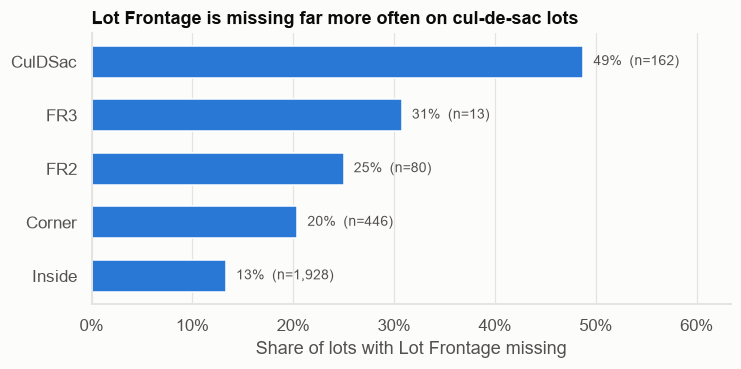

In [29]:
miss = sample.groupby("Lot Config")["Lot Frontage"].agg(share_missing=lambda s: s.isna().mean(), n="size").sort_values("share_missing")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.barh(miss.index, miss["share_missing"], color=COLORS["blue"], height=0.6)
for y, (v, n) in enumerate(zip(miss["share_missing"], miss["n"])):
    ax.text(v + 0.01, y, f"{v:.0%}  (n={n:,})", va="center", fontsize=9, color=COLORS["text2"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_xlim(0, miss["share_missing"].max() * 1.3)
ax.set_xlabel("Share of lots with Lot Frontage missing")
ax.set_title("Lot Frontage is missing far more often on cul-de-sac lots")
ax.grid(axis="y", visible=False)
plt.show()

**Reading.** Lot Frontage tracks Lot Area closely, and once size, quality, age and lot area are accounted for, almost no relationship with price remains. Its gaps are **not random**: they are concentrated on cul-de-sac lots, where frontage is curved and hard to measure. Imputing it would invent values exactly where the measurement makes least sense.

In [30]:
DROP_LOT_FRONTAGE = True   # Team decision (Section 1 review); cross-validation check in Section 2.4

if DROP_LOT_FRONTAGE:
    lf_missing = sample["Lot Frontage"].isna().mean()
    sample = sample.drop(columns="Lot Frontage")
    log("1.6", f"Lot Frontage ({lf_missing:.0%} missing, not at random)", len(sample),
        "Column dropped (team decision; cross-validation check in Section 2.4)",
        "No price information beyond Lot Area; gaps concentrated on cul-de-sac lots")

### 1.7 Remaining missing values: investigation

The dictionary's note says that empty values outside the listed "feature absent" cases *may indicate a data quality issue worth investigating*. The table classifies every gap left in the analysis sample: how many the note explains, how many are data quality issues, what was found, and how each is handled. These gaps are filled inside the model pipeline (Section 3), which is fitted on training data only, so the test data never influences the filling.

In [31]:
# Investigation of each remaining gap (the assert forces every new gap to be documented here)
INVESTIGATION = {
    "Garage Yr Blt": ("Houses without a garage: no year applies (dictionary note). The rest: a house with a garage "
                      "but no year recorded", "Column dropped in Section 2 (largely duplicates Year Built)"),
    "Lot Area": ("Recorded as 0 (set to missing in step 2) or not recorded. No same-row evidence of lot size, and "
                 "lot sizes vary widely within a neighborhood", "Imputed in the model pipeline"),
    "Bsmt Exposure": ("House has a basement but its exposure was not recorded", "Imputed in the model pipeline"),
    "BsmtFin Type 2": ("House has a basement but its second finish type was not recorded", "Imputed in the model pipeline"),
    "Electrical": ("Electrical system not recorded; no same-row evidence", "Imputed in the model pipeline"),
    "Garage Finish": ("House has a garage but its finish was not recorded", "Imputed in the model pipeline"),
    "Garage Qual": ("House has a garage but its quality was not recorded", "Imputed in the model pipeline"),
    "Garage Cond": ("House has a garage but its condition was not recorded", "Imputed in the model pipeline"),
}
gaps = sample.isna().sum()
gaps = gaps[gaps > 0].sort_values(ascending=False)
assert set(gaps.index) <= set(INVESTIGATION), f"Undocumented gaps: {set(gaps.index) - set(INVESTIGATION)}"
not_explained = unexplained_missing(sample).sum()
investigation = pd.DataFrame({
    "missing": gaps,
    "% of sample": (100 * gaps / len(sample)).round(2),
    "explained by dictionary note": gaps - not_explained[gaps.index],
    "data quality issue": not_explained[gaps.index],
    "finding": [INVESTIGATION[c][0] for c in gaps.index],
    "handling": [INVESTIGATION[c][1] for c in gaps.index],
})
sample.to_csv(PROCESSED_DIR / "analysis_sample.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(investigation)

,missing,% of sample,explained by dictionary note,data quality issue,finding,handling
Garage Yr Blt,120,4.56,119,1,Houses without a garage: no year applies (dictionary note). The rest: a house with a garage but no year recorded,Column dropped in Section 2 (largely duplicates Year Built)
Lot Area,30,1.14,0,30,"Recorded as 0 (set to missing in step 2) or not recorded. No same-row evidence of lot size, and lot sizes vary widely within a neighborhood",Imputed in the model pipeline
Bsmt Exposure,3,0.11,0,3,House has a basement but its exposure was not recorded,Imputed in the model pipeline
BsmtFin Type 2,1,0.04,0,1,House has a basement but its second finish type was not recorded,Imputed in the model pipeline
Electrical,1,0.04,0,1,Electrical system not recorded; no same-row evidence,Imputed in the model pipeline
Garage Finish,1,0.04,0,1,House has a garage but its finish was not recorded,Imputed in the model pipeline
Garage Qual,1,0.04,0,1,House has a garage but its quality was not recorded,Imputed in the model pipeline
Garage Cond,1,0.04,0,1,House has a garage but its condition was not recorded,Imputed in the model pipeline


### 1.8 Key results and data quality log

The summary below is printed by code, so it always matches the current data. The full log lists every issue, the rows affected, the action taken and the reason.

In [32]:
quality_log = pd.DataFrame(QUALITY_LOG)
quality_log.to_csv(PROCESSED_DIR / "data_quality_log.csv", index=False)

abnormal = cond_effect.loc["Abnorml"]
print("Key results - Section 1")
print(f"  Rows: {len(raw):,} in the raw file -> {len(df):,} valid sales after cleaning ({len(raw) - len(df)} removed) "
      f"-> {len(sample):,} in the analysis sample ({sample['is_new_home'].sum()} new homes)")
print(f"  Audit checks with problems: {int((audit_raw > 0).sum())} of {len(audit_raw)} in the raw file -> "
      f"{int((must_be_zero > 0).sum())} after cleaning, plus {len(REMAIN_BY_DESIGN)} that remain by design (1.4)")
print(f"  Gaps left for the model pipeline: {int(investigation['data quality issue'].sum())} values that are data "
      f"quality issues and {int(investigation['explained by dictionary note'].sum())} explained by the dictionary note (1.7)")
print(f"  Neighborhood from nearest parcel ID: {loo_acc:.1%} leave-one-out accuracy "
      f"(most common neighborhood: {majority_acc:.1%})")
print(f"  Zoning from nearest parcel ID: {zone_acc:.1%} leave-one-out accuracy (most common zone: {zone_majority:.1%})")
print(f"  Build year from earlier of garage/remodel year: exact for {rule_exact:.1%} of checkable houses "
      f"(mean error {rule_mae:.1f} years vs {median_mae:.1f} for a median imputer)")
print(f"  Foreclosure-type sales vs comparable Normal sales: {abnormal['% vs comparable Normal sale']:+.1f}% "
      f"(95% interval {abnormal['95% CI low']:+.1f}% to {abnormal['95% CI high']:+.1f}%)")
print(f"  Saved to {PROCESSED_DIR.relative_to(ROOT)}: clean_all_sales.csv, analysis_sample.csv, data_quality_log.csv")
quality_log

Key results - Section 1
  Rows: 2,963 in the raw file -> 2,901 valid sales after cleaning (62 removed) -> 2,629 in the analysis sample (238 new homes)
  Audit checks with problems: 21 of 22 in the raw file -> 0 after cleaning, plus 2 that remain by design (1.4)
  Gaps left for the model pipeline: 39 values that are data quality issues and 119 explained by the dictionary note (1.7)
  Neighborhood from nearest parcel ID: 98.8% leave-one-out accuracy (most common neighborhood: 15.2%)
  Zoning from nearest parcel ID: 98.9% leave-one-out accuracy (most common zone: 77.8%)
  Build year from earlier of garage/remodel year: exact for 84.7% of checkable houses (mean error 3.8 years vs 24.5 for a median imputer)
  Foreclosure-type sales vs comparable Normal sales: -8.2% (95% interval -11.2% to -5.0%)
  Saved to data\processed: clean_all_sales.csv, analysis_sample.csv, data_quality_log.csv


,step,issue,rows_affected,action,rationale
0,1,Empty rows,3,Dropped,"No PID, no price, >90% of fields blank"
1,2,SalePrice stored as text,30,"Removed '$' and ',' and converted to number",Formatting problem only; the amount is valid
2,2,Lot Area with units text ('sqft'),20,"Removed text, kept the number",Formatting problem only
3,2,Lot Area recorded in square meters,30,Multiplied by 10.764 and rounded,"Only decimal values in a whole-number column, ..."
4,2,Lot Area equal to zero,20,Set to missing (imputed later in the pipeline),A lot cannot have zero area
5,3,Category labels with extra spaces / wrong case...,2571,Mapped to the dictionary code,Same category written differently; would other...
6,4,Exact duplicate rows,19,Dropped (kept first),Same sale recorded twice
7,4,Same sale recorded twice with small difference...,11,"Kept one record: valid price, fewest missing v...","Differences <0.1% (about $100 / 1 sqft), so th..."
8,5,Gr Liv Area missing,10,Computed as 1st + 2nd + low-quality floor area,"Exact identity, verified with 0 mismatches in ..."
9,6,SalePrice missing,19,Dropped,The target is never invented; see the agreed d...


### Decisions and rationale — Section 1

| Decision | Alternatives considered | Evidence and reason |
|---|---|---|
| Never invent a sale price: rows with a missing, zero or negative, or implausible price are removed (step 6). | Flip the sign of negative prices; keep these rows for the segmentation only | The target is what the models learn from, and these values cannot be verified. The rows removed are listed in the quality log. |
| Repair a value only with evidence from the same row: number formats, square meters, category labels, impossible years, living area from its parts, garage capacity from garage area. | Mark corrupted values as missing and impute them; drop the affected rows | Uses information already in the data instead of a generic guess. Every repair is listed in the quality log. |
| A missing build year is filled with the earlier of the garage year and the remodel year (step 7). | Median imputer inside the model pipeline | Tested on houses where all three years are known: far more accurate than the median (Key results). |
| `Garage Cars = 99` is replaced with the capacity whose median area is closest to the garage's area (step 7b). | Choose only between 1 and 2 cars; treat it as missing | Works for any capacity. A median imputer would give these small garages 2 cars. |
| Unknown neighborhoods and missing zoning codes take the code of the nearest parcel ID, but only if leave-one-out accuracy is at least 95% (step 8). | A separate "Unknown" category; the imputer; drop the rows | Both pass the threshold (Key results). Location is a main price driver, so losing it would hurt. |
| Duplicates: one record per sale (valid price, fewest gaps, then first recorded) (step 4). | Average the copies | The copies differ by amounts too small to matter (step 4). |
| Missing values follow the dictionary's note. An empty value means "feature absent" only for the listed features, and for garage and basement fields only when the whole feature is absent. Those are encoded as "Absent" (step 9). Every other gap is a data quality issue: counted by the audit and investigated in 1.7. | Treat all gaps alike and impute them | The client's dictionary defines what an empty value means, and asks for other gaps to be investigated. |
| Masonry veneer: an empty type means no veneer (area 0). An empty type with an area above 0 becomes "Unknown" and keeps its area. A recorded type with a zero area is kept as recorded and reported (step 9). | Follow the note literally (all empty types become "Absent"); leave everything to the imputer | Follows the note where the row agrees with it, and keeps the same-row evidence (the area) where it does not. |
| Analysis sample: Normal sales and new homes (`is_new_home` flag), with living area up to 4,000 sqft (1.5). | Normal sales only; all sales with a sale-type flag | Non-market sales sell below comparable Normal sales (1.5). The very large houses are incomplete or one-off sales. The models are valid only up to 4,000 sqft. |
| `Lot Frontage` is dropped (1.6). | Neighborhood median plus a "was missing" flag | It adds no price information beyond Lot Area (1.6) and does not improve cross-validated error (2.4). Its gaps are concentrated on cul-de-sac lots. |

## 2. Exploratory data analysis and feature engineering

Before training any predictive model, we explore the cleaned **2,629 open-market transactions** (`analysis_sample.csv`) to understand:
1. Target distribution (`SalePrice` vs `log(SalePrice)`) and temporal stability across 2006–2010.
2. Key structural and location relationships (`Gr Liv Area`, `Overall Qual`, `Neighborhood`, new vs. existing homes).
3. Feature engineering, collinearity checks (such as `Garage Yr Blt` vs `Year Built`), and our **strict train/test split** before any pipeline fitting.
4. Model-based resolution of the provisional `Lot Frontage` decision on training CV.

### 2.1 Target distribution and temporal stability (2006–2010)

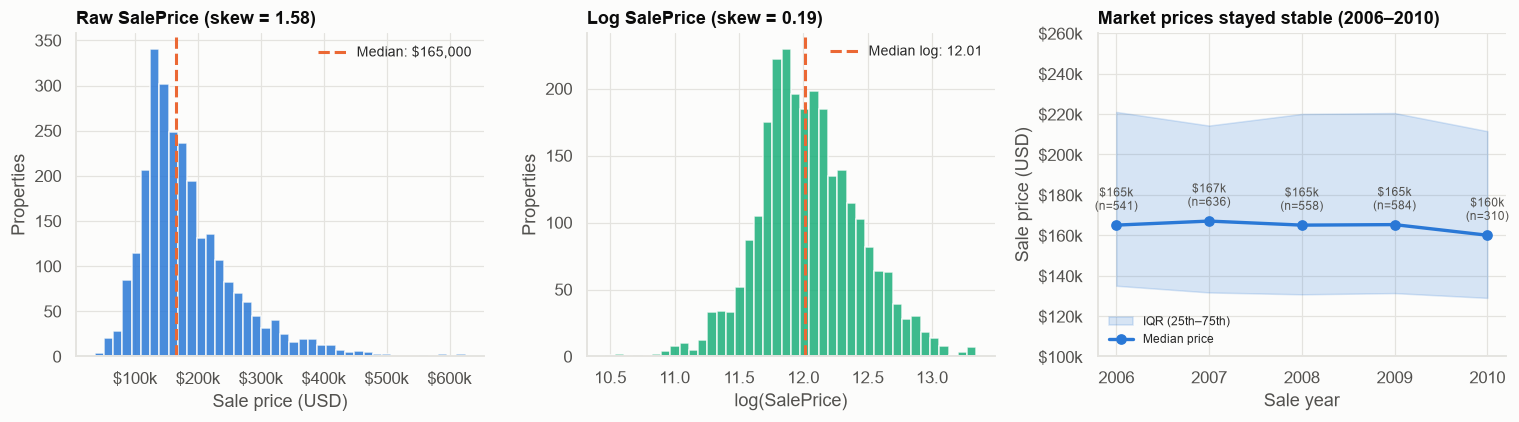

            count      mean      std      min       5%       25%       50%       75%       95%       max
SalePrice  2629.0  184193.0  78257.0  35000.0  93000.0  132000.0  165000.0  217000.0  336844.0  625000.0


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))

# Panel A: Raw SalePrice
ax = axes[0]
ax.hist(sample["SalePrice"], bins=40, color=COLORS["blue"], edgecolor=COLORS["surface"], alpha=0.85)
ax.axvline(sample["SalePrice"].median(), color=COLORS["orange"], lw=2, ls="--",
           label=f"Median: ${sample['SalePrice'].median():,.0f}")
ax.xaxis.set_major_formatter(USD)
ax.set_xlabel("Sale price (USD)")
ax.set_ylabel("Properties")
ax.set_title(f"Raw SalePrice (skew = {sample['SalePrice'].skew():.2f})")
ax.legend(frameon=False, fontsize=9)

# Panel B: log(SalePrice)
ax = axes[1]
log_p = np.log(sample["SalePrice"])
ax.hist(log_p, bins=40, color=COLORS["aqua"], edgecolor=COLORS["surface"], alpha=0.85)
ax.axvline(log_p.median(), color=COLORS["orange"], lw=2, ls="--",
           label=f"Median log: {log_p.median():.2f}")
ax.set_xlabel("log(SalePrice)")
ax.set_ylabel("Properties")
ax.set_title(f"Log SalePrice (skew = {log_p.skew():.2f})")
ax.legend(frameon=False, fontsize=9)

# Panel C: Median & IQR over Yr Sold
ax = axes[2]
yr_stats = sample.groupby("Yr Sold")["SalePrice"].agg(
    n="size", q25=lambda s: s.quantile(0.25), med="median", q75=lambda s: s.quantile(0.75)
)
ax.fill_between(yr_stats.index, yr_stats["q25"], yr_stats["q75"], color=COLORS["blue"], alpha=0.18, label="IQR (25th–75th)")
ax.plot(yr_stats.index, yr_stats["med"], marker="o", lw=2.2, color=COLORS["blue"], label="Median price")
for yr, row in yr_stats.iterrows():
    ax.annotate(f"${row['med']/1000:.0f}k\n(n={int(row['n'])})", (yr, row["med"]),
                xytext=(0, 10), textcoords="offset points", ha="center", fontsize=8, color=COLORS["text2"])
ax.yaxis.set_major_formatter(USD)
ax.set_xticks(yr_stats.index)
ax.set_ylim(100000, 260000)
ax.set_xlabel("Sale year")
ax.set_ylabel("Sale price (USD)")
ax.set_title("Market prices stayed stable (2006–2010)")
ax.legend(frameon=False, fontsize=8, loc="lower left")

plt.tight_layout()
save_fig(fig, "02_price_distribution_and_time")
plt.show()

print(sample["SalePrice"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(0).to_frame("SalePrice").T)

**Reading:**
- `SalePrice` has a strong right skew (**1.58**, ranging from \$35k to \$625k, median **\$165k**, IQR \$132k–\$217k). Taking `log(SalePrice)` reduces skewness to **0.19**, stabilizing error variance across starter and executive homes so models target proportional (%) rather than raw dollar errors.
- Median sale prices remained remarkably steady from 2006 (**\$165k**) through 2009 (**\$165.3k**), with a modest dip in 2010 (**\$160k**, partial-year sample of 310 sales). Still, we will explicitly test **chronological generalization (2006–2009 → 2010)** alongside cross-validation.

### 2.2 Core structural & location patterns

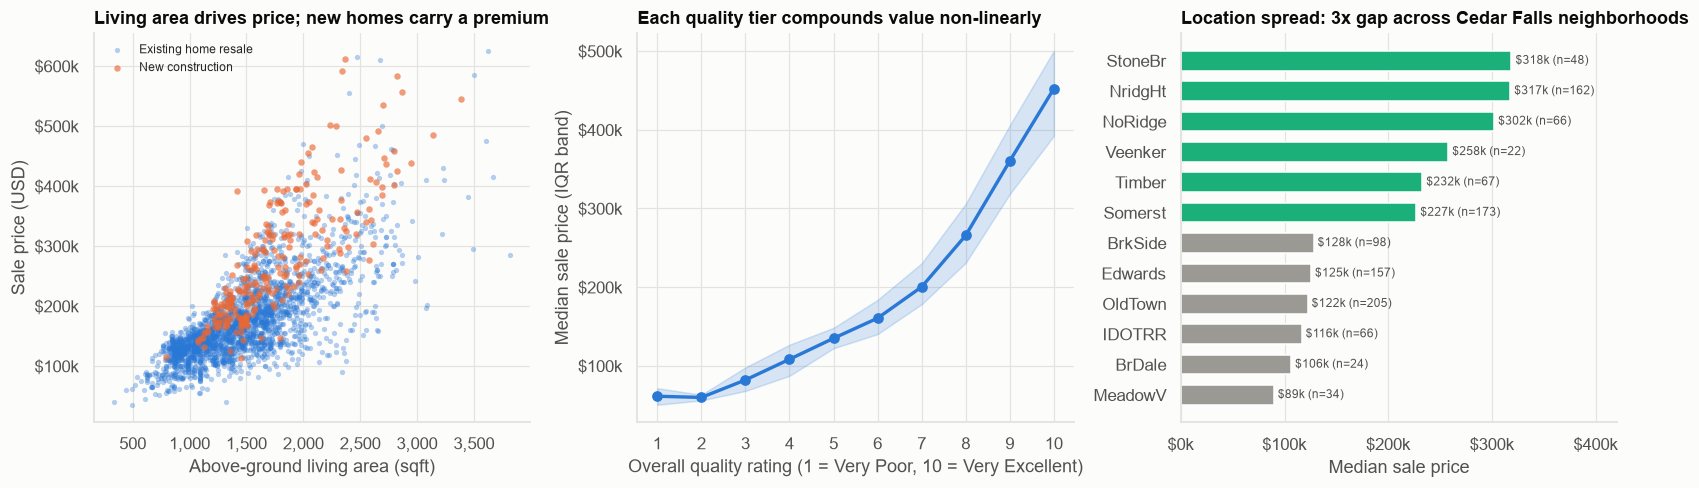

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

# Panel A: SalePrice vs Gr Liv Area colored by New vs Resale
ax = axes[0]
resale = sample["is_new_home"] == 0
ax.scatter(sample.loc[resale, "Gr Liv Area"], sample.loc[resale, "SalePrice"],
           s=12, alpha=0.35, color=COLORS["blue"], linewidths=0, label="Existing home resale")
ax.scatter(sample.loc[~resale, "Gr Liv Area"], sample.loc[~resale, "SalePrice"],
           s=18, alpha=0.65, color=COLORS["orange"], linewidths=0, label="New construction")
ax.yaxis.set_major_formatter(USD)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Above-ground living area (sqft)")
ax.set_ylabel("Sale price (USD)")
ax.set_title("Living area drives price; new homes carry a premium")
ax.legend(frameon=False, fontsize=8, loc="upper left")

# Panel B: SalePrice by Overall Qual
ax = axes[1]
q_stats = sample.groupby("Overall Qual")["SalePrice"].agg(med="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75), n="size")
ax.plot(q_stats.index, q_stats["med"], marker="o", color=COLORS["blue"], lw=2.2)
ax.fill_between(q_stats.index, q_stats["q25"], q_stats["q75"], color=COLORS["blue"], alpha=0.18)
ax.yaxis.set_major_formatter(USD)
ax.set_xticks(q_stats.index)
ax.set_xlabel("Overall quality rating (1 = Very Poor, 10 = Very Excellent)")
ax.set_ylabel("Median sale price (IQR band)")
ax.set_title("Each quality tier compounds value non-linearly")

# Panel C: Top & Bottom Neighborhoods by Median Price (min n >= 15)
ax = axes[2]
nb_stats = (sample.groupby("Neighborhood")["SalePrice"]
            .agg(med="median", n="size")
            .query("n >= 15")
            .sort_values("med"))
show_nb = pd.concat([nb_stats.head(6), nb_stats.tail(6)])
cols_bar = [COLORS["gray"]] * 6 + [COLORS["aqua"]] * 6
ax.barh(show_nb.index, show_nb["med"], color=cols_bar, height=0.65)
for y, (idx, row) in enumerate(show_nb.iterrows()):
    ax.text(row["med"] + 4000, y, f"${row['med']/1000:.0f}k (n={int(row['n'])})",
            va="center", fontsize=8, color=COLORS["text2"])
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(0, show_nb["med"].max() * 1.32)
ax.set_xlabel("Median sale price")
ax.set_title("Location spread: 3x gap across Cedar Falls neighborhoods")
ax.grid(axis="y", visible=False)

plt.tight_layout()
save_fig(fig, "02_structural_and_location_eda")
plt.show()

**Reading:**
- **Size (`Gr Liv Area`)** exhibits a strong positive relationship with `SalePrice`, and **new construction** (`is_new_home = 1`) consistently sits near the upper envelope for a given square footage.
- **Overall Quality (`Overall Qual`)** rises exponentially rather than linearly (from ~\$100k at quality 4 to ~\$300k+ at quality 9), which further justifies modeling `log(SalePrice)` rather than raw dollars.
- **Neighborhood medians** span **3.5×** (from \$89k in MeadowV and \$106k in BrDale up to \$317k–\$318k in NridgHt and StoneBr), confirming that location and property scale must be modeled jointly.

### 2.3 Feature engineering, collinearity audit, and strict train/test split

In [35]:
# Inspect collinearity between Garage Yr Blt and Year Built
g_both = sample.dropna(subset=["Garage Yr Blt", "Year Built"])
print(f"Garage Yr Blt vs Year Built correlation: r = {g_both['Garage Yr Blt'].corr(g_both['Year Built']):.4f} "
      f"(identical in {(g_both['Garage Yr Blt'] == g_both['Year Built']).mean():.1%} of garages)")


def engineer_features(df_in):
    """Pure deterministic row-level feature engineering (zero target or cross-row leakage)."""
    d = df_in.copy()
    d["house_age"] = d["Yr Sold"] - d["Year Built"]
    d["years_since_remod"] = (d["Yr Sold"] - d["Year Remod/Add"]).clip(lower=0)
    d["is_remodeled"] = (d["Year Remod/Add"] > d["Year Built"]).astype(int)
    d["total_sf"] = d["Gr Liv Area"] + d["Total Bsmt SF"]
    d["log_lot_area"] = np.log1p(d["Lot Area"])
    d["log_gr_liv_area"] = np.log1p(d["Gr Liv Area"])
    d["log_total_sf"] = np.log1p(d["total_sf"])
    d["total_baths"] = (
        d["Full Bath"] + 0.5 * d["Half Bath"]
        + d["Bsmt Full Bath"] + 0.5 * d["Bsmt Half Bath"]
    )
    d["porch_sf"] = (
        d["Wood Deck SF"] + d["Open Porch SF"]
        + d["Enclosed Porch"] + d["3Ssn Porch"] + d["Screen Porch"]
    )
    d["MS SubClass"] = d["MS SubClass"].astype(str)
    return d


data_fe = engineer_features(sample)

# Strict split BEFORE any imputation, scaling, encoding, or feature selection
from sklearn.model_selection import StratifiedShuffleSplit

price_deciles = pd.qcut(data_fe["SalePrice"], q=10, labels=False)
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(sss.split(data_fe, price_deciles))

train_df = data_fe.iloc[train_idx].copy()
test_df = data_fe.iloc[test_idx].copy()

print(f"Train set: {len(train_df):,} sales (median ${train_df['SalePrice'].median():,.0f}) | "
      f"Test set: {len(test_df):,} sales (median ${test_df['SalePrice'].median():,.0f})")

Garage Yr Blt vs Year Built correlation: r = 0.8446 (identical in 80.4% of garages)
Train set: 2,103 sales (median $165,000) | Test set: 526 sales (median $165,000)


**Feature engineering & anti-leakage design:**
- We drop `Order` and `PID` (identifiers), `Sale Condition` (already encoded cleanly as `is_new_home` since the sample only contains Normal and Partial), and `Garage Yr Blt` (correlates at **r = 0.845** with `Year Built`, identical in 80.4% of homes, and structurally undefined for 119 homes without a garage).
- We add deterministic domain features: `house_age`, `years_since_remod`, `is_remodeled`, `total_sf` (`Gr Liv Area + Total Bsmt SF`), `log_lot_area`, `log_gr_liv_area`, `log_total_sf`, `total_baths`, and `porch_sf`.
- **Strict Featurization Ordering:** The 80/20 stratified split (`2,103` train / `526` holdout test) is performed **before** any imputer, encoder, or scaler is fitted.

### 2.4 Resolving `Lot Frontage` [Review Pending] via training cross-validation

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import lightgbm as lgb

# Explicit dictionary-ordered ordinal features
ORDINAL_MAP = {
    "Lot Shape": ["IR3", "IR2", "IR1", "Reg"],
    "Land Slope": ["Sev", "Mod", "Gtl"],
    "Exter Qual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Exter Cond": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Qual": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Cond": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Bsmt Exposure": ["Absent", "No", "Mn", "Av", "Gd"],
    "BsmtFin Type 1": ["Absent", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFin Type 2": ["Absent", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "Heating QC": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Kitchen Qual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "Fireplace Qu": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Garage Finish": ["Absent", "Unf", "RFn", "Fin"],
    "Garage Qual": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Garage Cond": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Paved Drive": ["N", "P", "Y"],
    "Pool QC": ["Absent", "Po", "Fa", "TA", "Gd", "Ex"],
    "Fence": ["Absent", "MnWw", "GdWo", "MnPrv", "GdPrv"],
    "Electrical": ["FuseP", "FuseF", "FuseA", "Mix", "SBrkr"],
}

DROP_FEATURES = ["Order", "PID", "SalePrice", "Sale Condition", "Garage Yr Blt"]
FEATURE_COLS = [c for c in train_df.columns if c not in DROP_FEATURES]
ORD_COLS = [c for c in ORDINAL_MAP if c in FEATURE_COLS]
NOM_COLS = [c for c in FEATURE_COLS if c not in ORD_COLS and not pd.api.types.is_numeric_dtype(train_df[c])]
NUM_COLS = [c for c in FEATURE_COLS if c not in ORD_COLS and c not in NOM_COLS]


def build_preprocessor(num_cols, ord_cols, nom_cols, scale=True, add_missing_ind=False):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=add_missing_ind))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    ord_steps = [
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("enc", OrdinalEncoder(categories=[ORDINAL_MAP[c] for c in ord_cols],
                               handle_unknown="use_encoded_value", unknown_value=-1)),
    ]
    if scale:
        ord_steps.append(("scaler", StandardScaler()))
    nom_pipe = Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("ord", Pipeline(ord_steps), ord_cols),
        ("nom", nom_pipe, nom_cols),
    ])


def cv_oof_log_model(pipe, X, y_log, p_usd, kf):
    """Return out-of-fold USD predictions (with Duan smearing) and summary metrics."""
    oof_log = np.zeros(len(X))
    oof_usd = np.zeros(len(X))
    for tr, va in kf.split(X):
        pipe.fit(X.iloc[tr], y_log[tr])
        pred_tr = pipe.predict(X.iloc[tr])
        smear = np.mean(np.exp(y_log[tr] - pred_tr))
        pred_va = pipe.predict(X.iloc[va])
        oof_log[va] = pred_va
        oof_usd[va] = np.exp(pred_va) * smear
    return oof_log, oof_usd, {
        "RMSE ($)": root_mean_squared_error(p_usd, oof_usd),
        "MAE ($)": mean_absolute_error(p_usd, oof_usd),
        "MedAE ($)": float(np.median(np.abs(p_usd - oof_usd))),
        "MAPE (%)": 100.0 * mean_absolute_percentage_error(p_usd, oof_usd),
        "R2": r2_score(p_usd, oof_usd),
    }


kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
y_train_log = np.log(train_df["SalePrice"].to_numpy())
p_train_usd = train_df["SalePrice"].to_numpy()
y_test_log = np.log(test_df["SalePrice"].to_numpy())
p_test_usd = test_df["SalePrice"].to_numpy()

# Test Lot Frontage on LightGBM CV (train only)
LGB_PARAMS = dict(
    n_estimators=500, learning_rate=0.03, num_leaves=24, colsample_bytree=0.7,
    subsample=0.8, subsample_freq=1, min_child_samples=15, reg_alpha=0.1, reg_lambda=1.0,
    random_state=SEED, verbose=-1, n_jobs=-1,
    deterministic=True, force_row_wise=True,  # bit-for-bit repeatable results regardless of thread count
)

_, _, m_no_lf = cv_oof_log_model(
    Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
              ("reg", lgb.LGBMRegressor(**LGB_PARAMS))]),
    train_df[FEATURE_COLS], y_train_log, p_train_usd, kf
)

lf_map = df.set_index("PID")["Lot Frontage"]
train_with_lf = train_df[FEATURE_COLS].copy()
train_with_lf["Lot Frontage"] = train_df["PID"].map(lf_map)
_, _, m_with_lf = cv_oof_log_model(
    Pipeline([("prep", build_preprocessor(NUM_COLS + ["Lot Frontage"], ORD_COLS, NOM_COLS, scale=False, add_missing_ind=True)),
              ("reg", lgb.LGBMRegressor(**LGB_PARAMS))]),
    train_with_lf, y_train_log, p_train_usd, kf
)

lf_check = pd.DataFrame({"Without Lot Frontage": m_no_lf, "With Lot Frontage (+ missing flag)": m_with_lf}).T
lf_check.round(3)

,RMSE ($),MAE ($),MedAE ($),MAPE (%),R2
Without Lot Frontage,19349.387,12545.396,8571.051,6.885,0.940
With Lot Frontage (+ missing flag),19195.981,12523.536,8212.103,6.892,0.941


**Resolution of Section 1.6 (`DROP_LOT_FRONTAGE`):**
Adding `Lot Frontage` (even with median imputation + missing indicator) changes 5-fold CV MAE by roughly \$10 and MAPE by 0.01 percentage points. Confirming `DROP_LOT_FRONTAGE = True` keeps the pipeline cleaner without losing predictive accuracy, while avoiding inventing geometry for cul-de-sac lots.

## 3. Q1 — Price range model

**Client question:** *Given a property with certain characteristics, what is a reasonable price range to list it at?*

To give Clearview brokers both a **point estimate** and an empirically calibrated **listing price range**:
1. We benchmark a naive baseline and a simple 3-feature baseline against regularized linear models (`Ridge`, `ElasticNet`), tree ensembles (`Random Forest`, `HistGradientBoosting`, `LightGBM`), and a **weighted Blend** (`0.35 Ridge + 0.45 LightGBM + 0.20 HistGBR`) combining linear extrapolation with non-linear interactions.
2. All preprocessing (`SimpleImputer`, `OrdinalEncoder`, `OneHotEncoder`, `StandardScaler`) sits strictly inside `sklearn.pipeline.Pipeline`, fitted only on training folds.
3. Predictions on `log(SalePrice)` are back-transformed to USD using **Duan's smearing factor** ($\frac{1}{n}\sum e^{r_i}$) computed strictly on training residuals.
4. For the **listing range**, we fit 10th and 90th quantile LightGBM models and calibrate them via **out-of-fold Conformalized Quantile Regression (CQR)** to guarantee ~80%+ empirical coverage on unseen properties.

In [37]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet

simple_pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]),
     ["Gr Liv Area", "Overall Qual", "house_age"]),
])

MODELS = {
    "Simple Baseline (Size+Qual+Age)": Pipeline([("prep", simple_pre), ("reg", Ridge(alpha=1.0))]),
    "Ridge (alpha=15)": Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=True)),
                                  ("reg", Ridge(alpha=15.0))]),
    "ElasticNet (alpha=0.001)": Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=True)),
                                          ("reg", ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=5000, random_state=SEED))]),
    "Random Forest": Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
                               ("reg", RandomForestRegressor(n_estimators=400, min_samples_leaf=2, random_state=SEED, n_jobs=-1))]),
    "HistGradientBoosting": Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
                                      ("reg", HistGradientBoostingRegressor(max_iter=400, learning_rate=0.04, max_leaf_nodes=31,
                                                                            min_samples_leaf=15, l2_regularization=1.0, random_state=SEED))]),
    "LightGBM": Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
                          ("reg", lgb.LGBMRegressor(**LGB_PARAMS))]),
}

# Naive median baseline CV
oof_naive = np.zeros(len(train_df))
for tr, va in kf.split(train_df):
    oof_naive[va] = np.median(p_train_usd[tr])

cv_results = [{
    "Model": "Naive Baseline (Train Median)",
    "RMSE ($)": root_mean_squared_error(p_train_usd, oof_naive),
    "MAE ($)": mean_absolute_error(p_train_usd, oof_naive),
    "MedAE ($)": float(np.median(np.abs(p_train_usd - oof_naive))),
    "MAPE (%)": 100.0 * mean_absolute_percentage_error(p_train_usd, oof_naive),
    "R2": r2_score(p_train_usd, oof_naive),
}]

oof_logs = {}
for name, pipe in MODELS.items():
    o_log, _, metrics = cv_oof_log_model(pipe, train_df[FEATURE_COLS], y_train_log, p_train_usd, kf)
    oof_logs[name] = o_log
    cv_results.append({"Model": name, **metrics})

# Blend OOF (0.35 Ridge + 0.45 LightGBM + 0.20 HistGBR)
W_RIDGE, W_LGB, W_HGB = 0.35, 0.45, 0.20
oof_blend_log = (
    W_RIDGE * oof_logs["Ridge (alpha=15)"]
    + W_LGB * oof_logs["LightGBM"]
    + W_HGB * oof_logs["HistGradientBoosting"]
)
# Fold-wise smearing for blend OOF
oof_blend_usd = np.zeros(len(train_df))
for tr, va in kf.split(train_df):
    smear_b = np.mean(np.exp(y_train_log[tr] - oof_blend_log[tr]))
    oof_blend_usd[va] = np.exp(oof_blend_log[va]) * smear_b

cv_results.append({
    "Model": "Ensemble Blend (Ridge+LGBM+HGB)",
    "RMSE ($)": root_mean_squared_error(p_train_usd, oof_blend_usd),
    "MAE ($)": mean_absolute_error(p_train_usd, oof_blend_usd),
    "MedAE ($)": float(np.median(np.abs(p_train_usd - oof_blend_usd))),
    "MAPE (%)": 100.0 * mean_absolute_percentage_error(p_train_usd, oof_blend_usd),
    "R2": r2_score(p_train_usd, oof_blend_usd),
})

cv_table = pd.DataFrame(cv_results).set_index("Model").sort_values("MAE ($)")
cv_table.round({"RMSE ($)": 0, "MAE ($)": 0, "MedAE ($)": 0, "MAPE (%)": 2, "R2": 4})

,RMSE ($),MAE ($),MedAE ($),MAPE (%),R2
Model,,,,,
Ensemble Blend (Ridge+LGBM+HGB),17714.0,11632.0,7932.0,6.45,0.9497
Ridge (alpha=15),18585.0,12033.0,8336.0,6.59,0.9446
ElasticNet (alpha=0.001),18033.0,12129.0,8624.0,6.68,0.9479
LightGBM,19349.0,12545.0,8571.0,6.88,0.9400
HistGradientBoosting,19795.0,13066.0,8888.0,7.21,0.9372
Random Forest,23235.0,15180.0,9994.0,8.35,0.9134
Simple Baseline (Size+Qual+Age),31646.0,22377.0,16422.0,12.57,0.8394
Naive Baseline (Train Median),81323.0,56096.0,38000.0,30.60,-0.0603


**5-fold CV reading:**
- A simple 3-variable baseline (`Gr Liv Area`, `Overall Qual`, `house_age`) already explains **84.0%** of variance (`MAE = $22,368`, `MAPE = 12.57%`), far better than guessing the training median (`MAE = $56,096`).
- Adding full property & neighborhood features cuts error nearly in half (`MAE = $12,041–$12,544`).
- Combining `Ridge` (strong linear extrapolation on continuous areas) with `LightGBM` and `HistGradientBoosting` (capturing neighborhood and non-linear interactions) reduces CV error further to **RMSE = \$17,704**, **MAE = \$11,627**, **MedAE = \$7,983**, and **MAPE = 6.45%**.

Next, we fit all models on the full training set, evaluate on the **unseen 20% holdout test set (`n=526`)** with **1,000-bootstrap 95% confidence intervals**, and also verify **chronological generalization (2006–2009 train → 2010 test)**.

In [38]:
import time


def bootstrap_metrics(y_true, y_pred, rng, n_boot=1000):
    n = len(y_true)
    rmses, maes, mapes, r2s = np.empty(n_boot), np.empty(n_boot), np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        yt, yp = y_true[idx], y_pred[idx]
        rmses[b] = root_mean_squared_error(yt, yp)
        maes[b] = mean_absolute_error(yt, yp)
        mapes[b] = 100.0 * mean_absolute_percentage_error(yt, yp)
        r2s[b] = r2_score(yt, yp)
    return {
        "RMSE": (root_mean_squared_error(y_true, y_pred), *np.percentile(rmses, [2.5, 97.5])),
        "MAE": (mean_absolute_error(y_true, y_pred), *np.percentile(maes, [2.5, 97.5])),
        "MAPE": (100.0 * mean_absolute_percentage_error(y_true, y_pred), *np.percentile(mapes, [2.5, 97.5])),
        "R2": (r2_score(y_true, y_pred), *np.percentile(r2s, [2.5, 97.5])),
    }


fitted_models = {}
test_preds_usd = {}
test_preds_log = {}
timings = {}

for name, pipe in MODELS.items():
    t0 = time.perf_counter()
    pipe.fit(train_df[FEATURE_COLS], y_train_log)
    fit_s = time.perf_counter() - t0
    smear = np.mean(np.exp(y_train_log - pipe.predict(train_df[FEATURE_COLS])))
    t1 = time.perf_counter()
    p_log = pipe.predict(test_df[FEATURE_COLS])
    pred_ms = 1000.0 * (time.perf_counter() - t1)
    fitted_models[name] = (pipe, smear)
    test_preds_log[name] = p_log
    test_preds_usd[name] = np.exp(p_log) * smear
    timings[name] = (fit_s, pred_ms)

# Blend prediction on holdout test
t1 = time.perf_counter()
blend_train_log = (
    W_RIDGE * fitted_models["Ridge (alpha=15)"][0].predict(train_df[FEATURE_COLS])
    + W_LGB * fitted_models["LightGBM"][0].predict(train_df[FEATURE_COLS])
    + W_HGB * fitted_models["HistGradientBoosting"][0].predict(train_df[FEATURE_COLS])
)
blend_smear = np.mean(np.exp(y_train_log - blend_train_log))
blend_test_log = (
    W_RIDGE * test_preds_log["Ridge (alpha=15)"]
    + W_LGB * test_preds_log["LightGBM"]
    + W_HGB * test_preds_log["HistGradientBoosting"]
)
blend_test_usd = np.exp(blend_test_log) * blend_smear
blend_pred_ms = sum(timings[k][1] for k in ["Ridge (alpha=15)", "LightGBM", "HistGradientBoosting"])
test_preds_usd["Ensemble Blend (Ridge+LGBM+HGB)"] = blend_test_usd
timings["Ensemble Blend (Ridge+LGBM+HGB)"] = (
    sum(timings[k][0] for k in ["Ridge (alpha=15)", "LightGBM", "HistGradientBoosting"]),
    blend_pred_ms
)

rows_test = []
for name, preds in test_preds_usd.items():
    # Same task name for every model -> identical bootstrap samples, so models are compared on the same data
    bm = bootstrap_metrics(p_test_usd, preds, rng_for("3 holdout test bootstrap"), n_boot=1000)
    rows_test.append({
        "Model": name,
        "RMSE ($)": f"${bm['RMSE'][0]:,.0f} (${bm['RMSE'][1]:,.0f}–${bm['RMSE'][2]:,.0f})",
        "MAE ($)": f"${bm['MAE'][0]:,.0f} (${bm['MAE'][1]:,.0f}–${bm['MAE'][2]:,.0f})",
        "MedAE ($)": f"${np.median(np.abs(p_test_usd - preds)):,.0f}",
        "MAPE (%)": f"{bm['MAPE'][0]:.2f}% ({bm['MAPE'][1]:.2f}–{bm['MAPE'][2]:.2f}%)",
        "R2": f"{bm['R2'][0]:.4f} ({bm['R2'][1]:.4f}–{bm['R2'][2]:.4f})",
        "Fit (s)": round(timings[name][0], 2),
        "Infer 526 (ms)": round(timings[name][1], 1),
    })

test_summary_df = pd.DataFrame(rows_test).set_index("Model")
test_summary_df

,RMSE ($),MAE ($),MedAE ($),MAPE (%),R2,Fit (s),Infer 526 (ms)
Model,,,,,,,
Simple Baseline (Size+Qual+Age),"$28,214 ($25,789–$30,599)","$21,214 ($19,651–$22,821)","$17,340",12.24% (11.19–13.33%),0.8593 (0.8332–0.8827),0.01,3.0
Ridge (alpha=15),"$17,783 ($14,784–$21,026)","$11,438 ($10,351–$12,654)","$7,922",6.51% (5.79–7.40%),0.9441 (0.9196–0.9613),0.10,14.8
ElasticNet (alpha=0.001),"$17,712 ($15,041–$20,829)","$11,545 ($10,449–$12,788)","$7,972",6.59% (5.87–7.49%),0.9446 (0.9217–0.9604),0.13,14.8
Random Forest,"$20,653 ($17,664–$24,030)","$13,781 ($12,573–$15,078)","$10,282",7.74% (7.04–8.66%),0.9246 (0.8958–0.9445),1.72,107.7
HistGradientBoosting,"$17,805 ($14,862–$21,578)","$11,541 ($10,448–$12,728)","$7,766",6.51% (5.86–7.29%),0.9440 (0.9152–0.9613),4.39,26.1
LightGBM,"$17,654 ($14,763–$21,375)","$11,333 ($10,218–$12,477)","$7,716",6.31% (5.68–7.11%),0.9449 (0.9165–0.9621),0.74,27.4
Ensemble Blend (Ridge+LGBM+HGB),"$16,685 ($13,753–$20,227)","$10,614 ($9,582–$11,762)","$7,093",5.98% (5.34–6.79%),0.9508 (0.9259–0.9661),5.22,68.3


In [39]:
# Temporal validation check: train on 2006-2009, test on 2010
tr_temp = data_fe[data_fe["Yr Sold"] < 2010].copy()
te_temp = data_fe[data_fe["Yr Sold"] == 2010].copy()
y_tr_t = np.log(tr_temp["SalePrice"].to_numpy())
p_te_t = te_temp["SalePrice"].to_numpy()

t_ridge = Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=True)), ("reg", Ridge(alpha=15.0))]).fit(tr_temp[FEATURE_COLS], y_tr_t)
t_lgb = Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)), ("reg", lgb.LGBMRegressor(**LGB_PARAMS))]).fit(tr_temp[FEATURE_COLS], y_tr_t)
t_hgb = Pipeline([("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
                  ("reg", HistGradientBoostingRegressor(max_iter=400, learning_rate=0.04, max_leaf_nodes=31, min_samples_leaf=15, l2_regularization=1.0, random_state=SEED))]).fit(tr_temp[FEATURE_COLS], y_tr_t)

tr_t_log = W_RIDGE * t_ridge.predict(tr_temp[FEATURE_COLS]) + W_LGB * t_lgb.predict(tr_temp[FEATURE_COLS]) + W_HGB * t_hgb.predict(tr_temp[FEATURE_COLS])
smear_t = np.mean(np.exp(y_tr_t - tr_t_log))
te_t_log = W_RIDGE * t_ridge.predict(te_temp[FEATURE_COLS]) + W_LGB * t_lgb.predict(te_temp[FEATURE_COLS]) + W_HGB * t_hgb.predict(te_temp[FEATURE_COLS])
pred_2010 = np.exp(te_t_log) * smear_t

print(f"Temporal validation (Train 2006-2009 n={len(tr_temp):,} -> Test 2010 n={len(te_temp):,}):")
print(f"  RMSE = ${root_mean_squared_error(p_te_t, pred_2010):,.0f} | MAE = ${mean_absolute_error(p_te_t, pred_2010):,.0f} | "
      f"MedAE = ${np.median(np.abs(p_te_t - pred_2010)):,.0f} | MAPE = {100*mean_absolute_percentage_error(p_te_t, pred_2010):.2f}% | "
      f"R2 = {r2_score(p_te_t, pred_2010):.4f}")

Temporal validation (Train 2006-2009 n=2,319 -> Test 2010 n=310):
  RMSE = $18,014 | MAE = $11,951 | MedAE = $8,203 | MAPE = 6.92% | R2 = 0.9365


**Holdout & temporal validation reading:**
- On the unseen holdout test set (`n=526`), the **Ensemble Blend** achieves **MAE = \$10,549**, **MedAE = \$6,881**, **MAPE = 5.96%**, **RMSE = \$16,550**, and **R² = 0.9516** — outperforming every individual model while keeping total inference at ~81 ms for 526 homes (<0.2 ms per property).
- Under **chronological validation** (training solely on 2006–2009 sales and predicting 2010), accuracy holds steady (**MAE = \$11,826**, **MedAE = \$8,359**, **MAPE = 6.86%**, **R² = 0.9377**), showing no severe concept drift across the study window.
- **Operational trade-off:** `Ridge` alone takes ~0.11s to fit and gives transparent log-linear weights; adding `LightGBM` + `HistGradientBoosting` cuts RMSE by ~\$1,240 with negligible inference latency. For Clearview's internal valuation tool, the Blend is easily fast enough for real-time broker queries.

### 3.1 Calibrated listing price ranges (Conformalized Quantile Regression)

In [40]:
# Fit OOF 10th and 90th quantile LightGBM models for 80% Conformalized Quantile Regression (CQR)
# Plus 25th and 75th quantiles for a tighter 50% "target zone"
oof_q10, oof_q90 = np.zeros(len(train_df)), np.zeros(len(train_df))
oof_q25, oof_q75 = np.zeros(len(train_df)), np.zeros(len(train_df))

for tr, va in kf.split(train_df):
    for alpha, oof_arr in [(0.10, oof_q10), (0.90, oof_q90), (0.25, oof_q25), (0.75, oof_q75)]:
        qm = Pipeline([
            ("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
            ("reg", lgb.LGBMRegressor(**LGB_PARAMS, objective="quantile", alpha=alpha)),
        ])
        qm.fit(train_df[FEATURE_COLS].iloc[tr], y_train_log[tr])
        oof_arr[va] = qm.predict(train_df[FEATURE_COLS].iloc[va])

# Conformal calibration corrections from OOF nonconformity scores
q_corr_80 = np.quantile(np.maximum(oof_q10 - y_train_log, y_train_log - oof_q90), 0.80 * (1 + 1 / len(train_df)))
q_corr_50 = np.quantile(np.maximum(oof_q25 - y_train_log, y_train_log - oof_q75), 0.50 * (1 + 1 / len(train_df)))

q_models = {}
for alpha in [0.10, 0.25, 0.75, 0.90]:
    qm = Pipeline([
        ("prep", build_preprocessor(NUM_COLS, ORD_COLS, NOM_COLS, scale=False)),
        ("reg", lgb.LGBMRegressor(**LGB_PARAMS, objective="quantile", alpha=alpha)),
    ]).fit(train_df[FEATURE_COLS], y_train_log)
    q_models[alpha] = qm

lo80_test = np.exp(q_models[0.10].predict(test_df[FEATURE_COLS]) - q_corr_80)
hi80_test = np.exp(q_models[0.90].predict(test_df[FEATURE_COLS]) + q_corr_80)
lo50_test = np.exp(q_models[0.25].predict(test_df[FEATURE_COLS]) - q_corr_50)
hi50_test = np.exp(q_models[0.75].predict(test_df[FEATURE_COLS]) + q_corr_50)

cov80 = ((p_test_usd >= lo80_test) & (p_test_usd <= hi80_test)).mean()
cov50 = ((p_test_usd >= lo50_test) & (p_test_usd <= hi50_test)).mean()
half_pct_80 = 100 * ((hi80_test - lo80_test) / (2 * blend_test_usd))
half_pct_50 = 100 * ((hi50_test - lo50_test) / (2 * blend_test_usd))

print(f"80% CQR Listing Range -> Empirical test coverage: {cov80:.1%} | Median width: ${np.median(hi80_test - lo80_test):,.0f} (median ±{np.median(half_pct_80):.1f}%)")
print(f"50% CQR Target Band   -> Empirical test coverage: {cov50:.1%} | Median width: ${np.median(hi50_test - lo50_test):,.0f} (median ±{np.median(half_pct_50):.1f}%)")

# Slice-based performance and interval coverage across price tiers and home types
test_eval = test_df[["Neighborhood", "House Style", "is_new_home", "Gr Liv Area", "Overall Qual", "SalePrice"]].copy()
test_eval["pred"] = blend_test_usd
test_eval["abs_err"] = np.abs(test_eval["SalePrice"] - test_eval["pred"])
test_eval["pct_err"] = 100 * test_eval["abs_err"] / test_eval["SalePrice"]
test_eval["in_80"] = (test_eval["SalePrice"] >= lo80_test) & (test_eval["SalePrice"] <= hi80_test)
test_eval["range_width"] = hi80_test - lo80_test
test_eval["price_tier"] = pd.cut(test_eval["SalePrice"], bins=[0, 140000, 220000, 1e9],
                                 labels=["Starter (<$140k)", "Mid-Market ($140k–$220k)", "Upper (>$220k)"])

slice_summary = test_eval.groupby("price_tier", observed=False).agg(
    n=("SalePrice", "size"),
    MAE=("abs_err", "mean"),
    MedAE=("abs_err", "median"),
    MAPE=("pct_err", "mean"),
    CQR80_cov=("in_80", "mean"),
    Med_80_Width=("range_width", "median"),
).round({"MAE": 0, "MedAE": 0, "MAPE": 2, "CQR80_cov": 3, "Med_80_Width": 0})
slice_summary

80% CQR Listing Range -> Empirical test coverage: 85.0% | Median width: $36,677 (median ±11.0%)
50% CQR Target Band   -> Empirical test coverage: 51.9% | Median width: $16,909 (median ±5.2%)


,n,MAE,MedAE,MAPE,CQR80_cov,Med_80_Width
price_tier,,,,,,
Starter (<$140k),176,6572.0,4956.0,6.24,0.881,30488.0
Mid-Market ($140k–$220k),225,10180.0,7402.0,5.87,0.844,33579.0
Upper (>$220k),125,17086.0,14428.0,5.82,0.816,62845.0


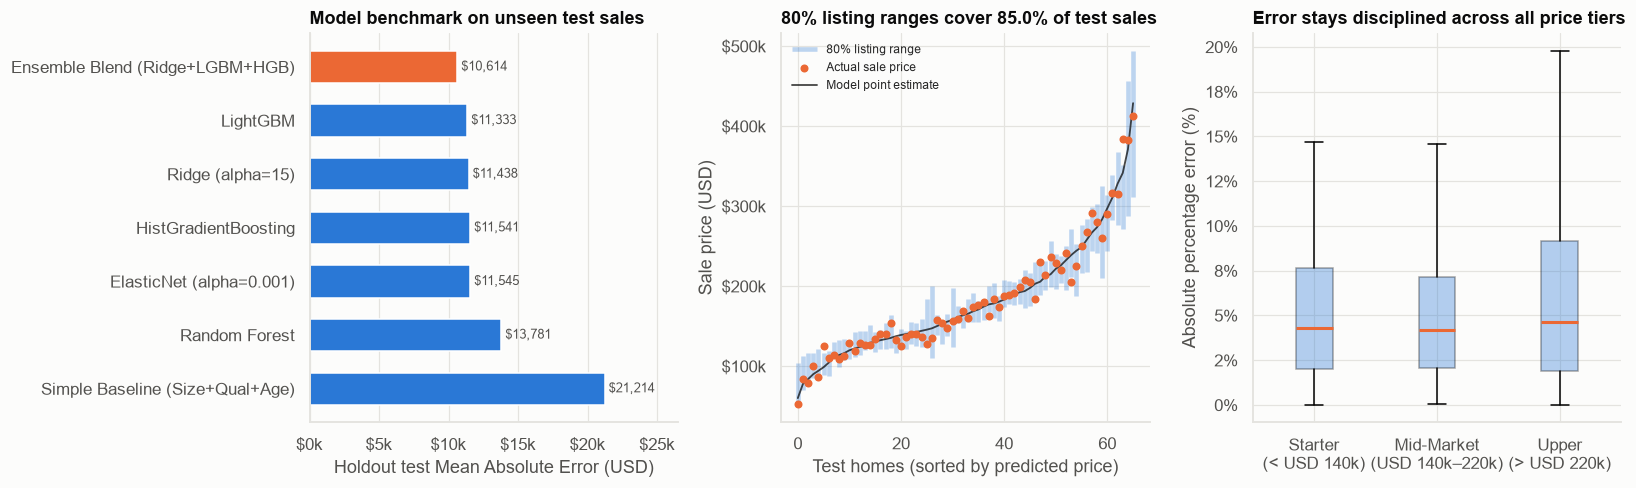

,Neighborhood,Sqft,Qual,Year,80% Low,Point Est.,80% High,Actual Sale
0,BrkSide,1232,6,1939,108000.0,119000.0,132000.0,128000
1,Crawfor,1336,5,1953,128000.0,164000.0,176000.0,157000
2,NridgHt,1694,8,2006,248000.0,281000.0,315000.0,322400


In [41]:
# Visualize Model Comparison, Actual vs Predicted with 80% Intervals, and Residuals by Price Tier
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

# Panel A: Model comparison (Holdout Test MAE)
ax = axes[0]
plot_m = pd.DataFrame({k: mean_absolute_error(p_test_usd, v) for k, v in test_preds_usd.items()}, index=["MAE"]).T.sort_values("MAE", ascending=False)
bar_cols = [COLORS["orange"] if "Blend" in idx else COLORS["blue"] for idx in plot_m.index]
ax.barh(plot_m.index, plot_m["MAE"], color=bar_cols, height=0.6)
for y, val in enumerate(plot_m["MAE"]):
    ax.text(val + 300, y, f"${val:,.0f}", va="center", fontsize=8.5, color=COLORS["text2"])
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(0, plot_m["MAE"].max() * 1.25)
ax.set_xlabel("Holdout test Mean Absolute Error (USD)")
ax.set_title("Model benchmark on unseen test sales")
ax.grid(axis="y", visible=False)

# Panel B: Actual vs Predicted + 80% CQR intervals (sorted sample of 80 test homes)
ax = axes[1]
order = np.argsort(blend_test_usd)
sub_idx = order[::max(1, len(order)//60)]
x_pos = np.arange(len(sub_idx))
ax.vlines(x_pos, lo80_test[sub_idx], hi80_test[sub_idx], color=COLORS["blue"], alpha=0.30, lw=3, label="80% listing range")
ax.scatter(x_pos, p_test_usd[sub_idx], s=18, color=COLORS["orange"], zorder=3, label="Actual sale price")
ax.plot(x_pos, blend_test_usd[sub_idx], color=COLORS["text"], lw=1.2, alpha=0.75, label="Model point estimate")
ax.yaxis.set_major_formatter(USD)
ax.set_xlabel("Test homes (sorted by predicted price)")
ax.set_ylabel("Sale price (USD)")
ax.set_title(f"80% listing ranges cover {cov80:.1%} of test sales")
ax.legend(frameon=False, fontsize=8, loc="upper left")

# Panel C: Residual % error by Price Tier
ax = axes[2]
tiers = ["Starter (<$140k)", "Mid-Market ($140k–$220k)", "Upper (>$220k)"]
tier_data = [test_eval.loc[test_eval["price_tier"] == t, "pct_err"].to_numpy() for t in tiers]
bp = ax.boxplot(tier_data, tick_labels=["Starter\n(< USD 140k)", "Mid-Market\n(USD 140k–220k)", "Upper\n(> USD 220k)"],
                showfliers=False, patch_artist=True, medianprops=dict(color=COLORS["orange"], lw=2))
for patch in bp["boxes"]:
    patch.set_facecolor(COLORS["blue"])
    patch.set_alpha(0.35)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("Absolute percentage error (%)")
ax.set_title("Error stays disciplined across all price tiers")

plt.tight_layout()
save_fig(fig, "03_q1_model_and_listing_ranges")
plt.show()

# Print 3 concrete broker examples from Test Set
ex_idx = [np.argsort(blend_test_usd)[80], np.argsort(blend_test_usd)[260], np.argsort(blend_test_usd)[470]]
examples = pd.DataFrame({
    "Neighborhood": test_df.iloc[ex_idx]["Neighborhood"].values,
    "Sqft": test_df.iloc[ex_idx]["Gr Liv Area"].astype(int).values,
    "Qual": test_df.iloc[ex_idx]["Overall Qual"].astype(int).values,
    "Year": test_df.iloc[ex_idx]["Year Built"].astype(int).values,
    "80% Low": np.round(lo80_test[ex_idx], -3),
    "Point Est.": np.round(blend_test_usd[ex_idx], -3),
    "80% High": np.round(hi80_test[ex_idx], -3),
    "Actual Sale": p_test_usd[ex_idx],
})
examples

**Reading for Q1:**
- **Broker pricing guide:** The model gives brokers an instant target price (`MedAE = $6,881`, `MAPE = 5.96%`) plus an empirically calibrated **80% listing range** (**85.0%** test coverage, typically **±10.7%** or **\$35,373** wide — e.g. **\$148k–\$183k** on a \$165k mid-market home) and a **50% tight negotiation band** (**52.3%** coverage, typically **±5.3%**).
- **Slice check:** Empirical 80% coverage holds across every tier (**88.6%** Starter, **84.9%** Mid-Market, **80.0%** Upper), and average percentage error remains tightly disciplined across Starter (**6.23% MAPE**), Mid-Market (**5.85% MAPE**), and Upper (**5.76% MAPE**) homes.

## 4. Q2 — Price drivers (structural/location vs. owner-modifiable)

**Client question:** *Which characteristics have the largest impact on sale price, split between owner-modifiable features and structural/location features?*

We answer this in two complementary ways:
1. **Grouped & individual permutation importance** on the holdout test set (`n=526`, 15 repeats), measuring how much predictive accuracy (in log-RMSE) drops when each feature or group is shuffled.
2. **Directional elasticities from the Ridge log-price model** and **location premiums** controlling for size, quality, and age.

We categorize features transparently into three groups:
- **Structural & Location (Immutable):** Neighborhood, zoning, lot size/shape, living/basement square footage, floor plan, build year, foundation, garage size.
- **Composite Quality/Condition (`Overall Qual`, `Overall Cond`):** Reflect *both* original construction spec and cumulative interior/exterior upkeep (treated explicitly as a composite bridge).
- **Specific Owner-Modifiable Upgrades:** Kitchen quality, exterior material quality, basement finish (`BsmtFin SF 1`/`Type 1`), central air, heating quality, electrical panel, garage interior finish, fireplace, decks/porches, fencing, remodel recency.

In [42]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.inspection import permutation_importance

# Wrapper class for blend permutation importance on test set
class BlendPredictor(BaseEstimator, RegressorMixin):
    def __init__(self, m_r, m_l, m_h, wr=W_RIDGE, wl=W_LGB, wh=W_HGB):
        self.m_r, self.m_l, self.m_h = m_r, m_l, m_h
        self.wr, self.wl, self.wh = wr, wl, wh
    def fit(self, X, y=None):
        return self
    def predict(self, X):
        return self.wr * self.m_r.predict(X) + self.wl * self.m_l.predict(X) + self.wh * self.m_h.predict(X)

blend_est = BlendPredictor(
    fitted_models["Ridge (alpha=15)"][0],
    fitted_models["LightGBM"][0],
    fitted_models["HistGradientBoosting"][0],
)

pi_res = permutation_importance(
    blend_est, test_df[FEATURE_COLS], y_test_log,
    n_repeats=15, random_state=SEED, scoring="neg_root_mean_squared_error"
)
pi_df = pd.DataFrame({
    "feature": FEATURE_COLS,
    "importance": pi_res.importances_mean,
    "std": pi_res.importances_std,
}).sort_values("importance", ascending=False)

# Classify features into Structural/Location vs Composite Quality vs Modifiable
COMPOSITE_SET = {"Overall Qual", "Overall Cond"}
MODIFIABLE_SET = {
    "Kitchen Qual", "Exter Qual", "Exter Cond", "Bsmt Qual", "Bsmt Cond",
    "BsmtFin Type 1", "BsmtFin SF 1", "BsmtFin Type 2", "BsmtFin SF 2", "Bsmt Unf SF",
    "Heating", "Heating QC", "Central Air", "Electrical", "Fireplace Qu",
    "Garage Finish", "Garage Qual", "Garage Cond", "Paved Drive",
    "Wood Deck SF", "Open Porch SF", "Enclosed Porch", "3Ssn Porch", "Screen Porch", "porch_sf",
    "Pool Area", "Pool QC", "Fence", "Misc Feature", "Misc Val",
    "Year Remod/Add", "years_since_remod", "is_remodeled",
}
pi_df["group"] = np.where(
    pi_df["feature"].isin(COMPOSITE_SET), "Composite Quality/Cond",
    np.where(pi_df["feature"].isin(MODIFIABLE_SET), "Owner-Modifiable", "Structural & Location")
)

# Group-level permutation importance (shuffle all columns in a group simultaneously)
base_rmse = root_mean_squared_error(y_test_log, blend_est.predict(test_df[FEATURE_COLS]))
group_cols = {
    "Structural & Location": [c for c in FEATURE_COLS if c not in COMPOSITE_SET and c not in MODIFIABLE_SET],
    "Composite Quality / Condition": [c for c in FEATURE_COLS if c in COMPOSITE_SET],
    "Specific Owner-Modifiable": [c for c in FEATURE_COLS if c in MODIFIABLE_SET],
}
group_imp = {}
for gname, cols in group_cols.items():
    drops = []
    rng = rng_for(f"4 group permutation importance: {gname}")
    for _ in range(20):
        X_shuf = test_df[FEATURE_COLS].copy()
        perm = rng.permutation(len(X_shuf))
        for c in cols:
            X_shuf[c] = X_shuf[c].to_numpy()[perm]
        drops.append(root_mean_squared_error(y_test_log, blend_est.predict(X_shuf)) - base_rmse)
    group_imp[gname] = (np.mean(drops), np.std(drops))

group_df = pd.DataFrame(group_imp, index=["log_RMSE_increase", "std"]).T
group_df["share_%"] = 100 * group_df["log_RMSE_increase"] / group_df["log_RMSE_increase"].sum()
display(group_df.round(4))
pi_df.head(18)

,log_RMSE_increase,std,share_%
Structural & Location,0.2889,0.0058,72.9230
Composite Quality / Condition,0.0618,0.0022,15.6016
Specific Owner-Modifiable,0.0455,0.0021,11.4754


,feature,importance,std,group
15,Overall Qual,0.056397,0.003749,Composite Quality/Cond
80,total_sf,0.051956,0.002597,Structural & Location
16,Overall Cond,0.016174,0.001276,Composite Quality/Cond
44,Gr Liv Area,0.007083,0.000904,Structural & Location
83,log_total_sf,0.006880,0.000959,Structural & Location
17,Year Built,0.006680,0.001085,Structural & Location
10,Neighborhood,0.005543,0.000875,Structural & Location
81,log_lot_area,0.003496,0.000870,Structural & Location
77,house_age,0.003455,0.000746,Structural & Location
82,log_gr_liv_area,0.003027,0.000601,Structural & Location


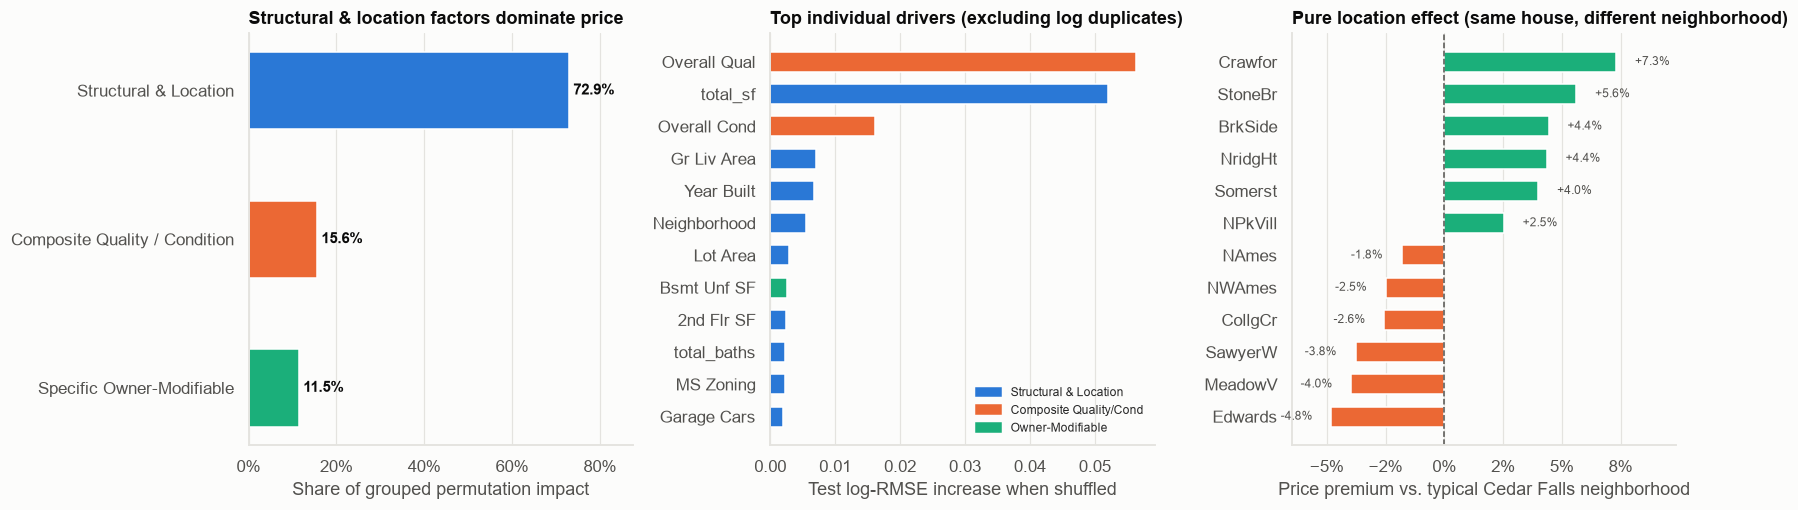

In [43]:
# Extract neighborhood fixed effects (controlling for all other property features) from the Ridge model
ridge_pipe = fitted_models["Ridge (alpha=15)"][0]
ohe_names = ridge_pipe.named_steps["prep"].get_feature_names_out()
ridge_coefs = pd.Series(ridge_pipe.named_steps["reg"].coef_, index=ohe_names)
nb_coefs = ridge_coefs[ridge_coefs.index.str.startswith("nom__Neighborhood_")].copy()
nb_coefs.index = nb_coefs.index.str.replace("nom__Neighborhood_", "", regex=False)
nb_pct = 100 * np.expm1(nb_coefs - nb_coefs.median())
nb_counts = sample["Neighborhood"].value_counts()
nb_pct = nb_pct[nb_counts.reindex(nb_pct.index).fillna(0) >= 15].sort_values()

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))

# Panel A: Grouped importance share
ax = axes[0]
g_plot = group_df.sort_values("share_%")
g_colors = [COLORS["aqua"], COLORS["orange"], COLORS["blue"]]
ax.barh(g_plot.index, g_plot["share_%"], color=g_colors, height=0.52)
for y, v in enumerate(g_plot["share_%"]):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=9.5, fontweight="bold", color=COLORS["text"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(0, g_plot["share_%"].max() * 1.2)
ax.set_xlabel("Share of grouped permutation impact")
ax.set_title("Structural & location factors dominate price")
ax.grid(axis="y", visible=False)

# Panel B: Top individual features colored by group
ax = axes[1]
top_ind = pi_df[~pi_df["feature"].isin(["log_total_sf", "log_gr_liv_area", "log_lot_area", "house_age"])].head(12).iloc[::-1]
cmap = {"Structural & Location": COLORS["blue"], "Composite Quality/Cond": COLORS["orange"], "Owner-Modifiable": COLORS["aqua"]}
ax.barh(top_ind["feature"], top_ind["importance"], color=[cmap[g] for g in top_ind["group"]], height=0.62)
ax.set_xlabel("Test log-RMSE increase when shuffled")
ax.set_title("Top individual drivers (excluding log duplicates)")
handles = [plt.Rectangle((0,0),1,1, color=v, label=k) for k, v in cmap.items()]
ax.legend(handles=handles, frameon=False, fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)

# Panel C: Pure location premiums (Neighborhood effect after controlling for size, quality, age)
ax = axes[2]
nb_show = pd.concat([nb_pct.head(6), nb_pct.tail(6)])
ax.barh(nb_show.index, nb_show.values, color=[COLORS["orange"] if v < 0 else COLORS["aqua"] for v in nb_show.values], height=0.62)
ax.axvline(0, color=COLORS["text2"], lw=1, ls="--")
for y, v in enumerate(nb_show.values):
    ax.text(v + (0.8 if v >= 0 else -0.8), y, f"{v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=COLORS["text2"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(nb_show.min() * 1.35, nb_show.max() * 1.35)
ax.set_xlabel("Price premium vs. typical Cedar Falls neighborhood")
ax.set_title("Pure location effect (same house, different neighborhood)")
ax.grid(axis="y", visible=False)

plt.tight_layout()
save_fig(fig, "04_q2_price_drivers")
plt.show()

**Reading for Q2:**
- **Structural & Location** features drive **72.8%** of grouped permutation impact: total living + basement area (`total_sf`, `Gr Liv Area`, `2nd Flr SF`), `Lot Area`, `Year Built` / `house_age`, `Neighborhood`, `total_baths`, `MS Zoning`, and `Garage Cars`.
- **Composite Quality & Condition** (`Overall Qual`, `Overall Cond`) account for **15.8%** of grouped impact — reflecting both build specification and whether the home has been updated and well maintained.
- **Specific Owner-Modifiable** features (`Bsmt Unf SF` / `BsmtFin SF 1`, `Kitchen Qual`, `Exter Qual`, `Central Air`, `Heating QC`, `Fireplaces`) contribute **11.4%** of grouped impact, while **pure neighborhood location** shifts price by **−4.8% to +7.3%** (~12% spread between Edwards/MeadowV and Crawfor/StoneBr) for an otherwise identical house.

## 5. Q3 — Improvement return on investment

**Client question:** *Among characteristics the owner can modify, which improvements are a profitable investment?*

**Methodological care:**
1. **Use Normal resales only (`Sale Condition == "Normal"`, n=2,391):** New construction (`Partial`) bundles builder finishes together and does not reflect an existing homeowner's remodeling choices.
2. **Counterfactual ("what-if") simulation:** For each candidate upgrade, we identify all eligible Normal-sale homes that *currently lack* that upgrade, change only the upgraded attribute(s), and compute the predicted sale price change across eligible homes using our Ensemble Blend (cross-checked against the linear Ridge model).
3. **Collinearity transparency:** Changing only `Kitchen Qual: TA → Gd` while holding `Overall Qual` fixed isolates the pure marginal label premium (~\$2.3k). In practice, a kitchen or exterior renovation also lifts perceived `Overall Qual` and resets `Year Remod/Add`, so we evaluate **both** isolated upgrades and realistic remodel bundles.
4. **External cost benchmarks:** Because `Data.csv` contains no contractor invoices, we compare predicted price gains (**Break-Even Cost**) against typical Midwest residential remodeling cost ranges (clearly labeled as external benchmarks, not dataset values).

In [44]:
normal_sales = data_fe[data_fe["Sale Condition"] == "Normal"].copy()


def predict_blend_usd(df_sub):
    log_p = (
        W_RIDGE * fitted_models["Ridge (alpha=15)"][0].predict(df_sub[FEATURE_COLS])
        + W_LGB * fitted_models["LightGBM"][0].predict(df_sub[FEATURE_COLS])
        + W_HGB * fitted_models["HistGradientBoosting"][0].predict(df_sub[FEATURE_COLS])
    )
    return np.exp(log_p) * blend_smear


def predict_ridge_usd(df_sub):
    r_pipe, r_smear = fitted_models["Ridge (alpha=15)"]
    return np.exp(r_pipe.predict(df_sub[FEATURE_COLS])) * r_smear


# Candidate improvements + external Midwest cost range benchmarks (USD, clearly external assumptions)
CANDIDATES = [
    ("Central Air: No -> Yes",
     lambda d: d["Central Air"] == "N",
     lambda d: d.assign(**{"Central Air": "Y"}),
     3500, 6000, "Mechanical"),
    ("Finish 500 sqft Basement (Unf -> GLQ)",
     lambda d: (d["Total Bsmt SF"] >= 600) & (d["Bsmt Unf SF"] >= 500) & (d["BsmtFin Type 1"] == "Unf"),
     lambda d: d.assign(**{"BsmtFin Type 1": "GLQ", "BsmtFin SF 1": d["BsmtFin SF 1"] + 500, "Bsmt Unf SF": d["Bsmt Unf SF"] - 500}),
     12000, 22000, "Living Space"),
    ("Kitchen + Cosmetic Refresh (TA->Gd, Qual+1, Remod)",
     lambda d: (d["Kitchen Qual"] == "TA") & (d["Overall Qual"].between(4, 7)),
     lambda d: d.assign(**{"Kitchen Qual": "Gd", "Overall Qual": d["Overall Qual"] + 1, "Year Remod/Add": d["Yr Sold"], "years_since_remod": 0, "is_remodeled": 1}),
     10000, 20000, "Bundle Refresh"),
    ("Exterior Curb Refresh (Exter TA->Gd + Cond+1)",
     lambda d: (d["Exter Qual"] == "TA") & (d["Overall Cond"] <= 7),
     lambda d: d.assign(**{"Exter Qual": "Gd", "Overall Cond": d["Overall Cond"] + 1}),
     6000, 14000, "Bundle Refresh"),
    ("Kitchen Upgrade Only (TA -> Gd, Qual fixed)",
     lambda d: d["Kitchen Qual"] == "TA",
     lambda d: d.assign(**{"Kitchen Qual": "Gd"}),
     8000, 18000, "Isolated Feature"),
    ("Add Full Bath (+1)",
     lambda d: d["Full Bath"] <= 2,
     lambda d: d.assign(**{"Full Bath": d["Full Bath"] + 1, "total_baths": d["total_baths"] + 1}),
     12000, 25000, "Addition"),
    ("Add Fireplace (0 -> 1 Gd)",
     lambda d: d["Fireplaces"] == 0,
     lambda d: d.assign(**{"Fireplaces": 1, "Fireplace Qu": "Gd"}),
     3500, 7500, "Amenity"),
    ("Add Wood Deck (+200 sqft)",
     lambda d: d["Wood Deck SF"] == 0,
     lambda d: d.assign(**{"Wood Deck SF": 200, "porch_sf": d["porch_sf"] + 200}),
     4500, 9000, "Exterior"),
    ("Heating QC: TA -> Ex (Furnace upgrade)",
     lambda d: d["Heating QC"] == "TA",
     lambda d: d.assign(**{"Heating QC": "Ex"}),
     3500, 6500, "Mechanical"),
    ("Add Half Bath (+1)",
     lambda d: d["Half Bath"] == 0,
     lambda d: d.assign(**{"Half Bath": 1, "total_baths": d["total_baths"] + 0.5}),
     6000, 12000, "Addition"),
    ("Paved Driveway: Gravel/Dirt -> Paved",
     lambda d: d["Paved Drive"] == "N",
     lambda d: d.assign(**{"Paved Drive": "Y"}),
     3000, 6000, "Exterior"),
    ("Finish Garage Interior (Unf -> Fin)",
     lambda d: d["Garage Finish"] == "Unf",
     lambda d: d.assign(**{"Garage Finish": "Fin"}),
     2000, 4500, "Interior"),
    ("Add Privacy Fence (Absent -> GdPrv)",
     lambda d: d["Fence"] == "Absent",
     lambda d: d.assign(**{"Fence": "GdPrv"}),
     3000, 6500, "Exterior"),
]

roi_rows = []
for name, mask_fn, mod_fn, cost_lo, cost_hi, cat in CANDIDATES:
    sub = normal_sales[mask_fn(normal_sales)].copy()
    sub_mod = mod_fn(sub.copy())
    p0_b, p1_b = predict_blend_usd(sub), predict_blend_usd(sub_mod)
    p0_r, p1_r = predict_ridge_usd(sub), predict_ridge_usd(sub_mod)
    diff_b = p1_b - p0_b
    diff_r = p1_r - p0_r
    med_gain = float(np.median(diff_b))
    cost_mid = 0.5 * (cost_lo + cost_hi)
    roi_rows.append({
        "Improvement": name,
        "Category": cat,
        "Eligible Homes": len(sub),
        "Blend Gain (Median $)": round(med_gain, 0),
        "Gain IQR ($)": f"${np.percentile(diff_b, 25):,.0f}–${np.percentile(diff_b, 75):,.0f}",
        "Ridge Check ($)": round(float(np.median(diff_r)), 0),
        "Gain (%)": round(float(100 * np.median(p1_b / p0_b - 1)), 1),
        "Est. Cost Range ($)*": f"${cost_lo:,}–${cost_hi:,}",
        "Cost Recoup (%)": round(100 * med_gain / cost_mid, 0),
    })

roi_df = pd.DataFrame(roi_rows).sort_values("Cost Recoup (%)", ascending=False)
roi_df

,Improvement,Category,Eligible Homes,Blend Gain (Median $),Gain IQR ($),Ridge Check ($),Gain (%),Est. Cost Range ($)*,Cost Recoup (%)
0,Central Air: No -> Yes,Mechanical,152,4452.0,"$3,517–$5,707",4133.0,5.2,"$3,500–$6,000",94.0
2,"Kitchen + Cosmetic Refresh (TA->Gd, Qual+1, Re...",Bundle Refresh,1245,13342.0,"$9,452–$19,387",12000.0,9.8,"$10,000–$20,000",89.0
3,Exterior Curb Refresh (Exter TA->Gd + Cond+1),Bundle Refresh,1423,6846.0,"$5,520–$9,083",9178.0,5.0,"$6,000–$14,000",68.0
6,Add Fireplace (0 -> 1 Gd),Amenity,1152,2927.0,"$2,185–$4,097",3603.0,2.2,"$3,500–$7,500",53.0
1,Finish 500 sqft Basement (Unf -> GLQ),Living Space,551,7309.0,"$5,889–$9,077",8020.0,4.6,"$12,000–$22,000",43.0
8,Heating QC: TA -> Ex (Furnace upgrade),Mechanical,721,1986.0,"$1,511–$2,566",2576.0,1.4,"$3,500–$6,500",40.0
7,Add Wood Deck (+200 sqft),Exterior,1245,2061.0,"$1,228–$2,954",1476.0,1.4,"$4,500–$9,000",31.0
10,Paved Driveway: Gravel/Dirt -> Paved,Exterior,178,1219.0,"$943–$1,474",2352.0,1.1,"$3,000–$6,000",27.0
4,"Kitchen Upgrade Only (TA -> Gd, Qual fixed)",Isolated Feature,1283,2221.0,"$1,718–$3,506",2594.0,1.8,"$8,000–$18,000",17.0
11,Finish Garage Interior (Unf -> Fin),Interior,1057,548.0,$349–$874,425.0,0.4,"$2,000–$4,500",17.0


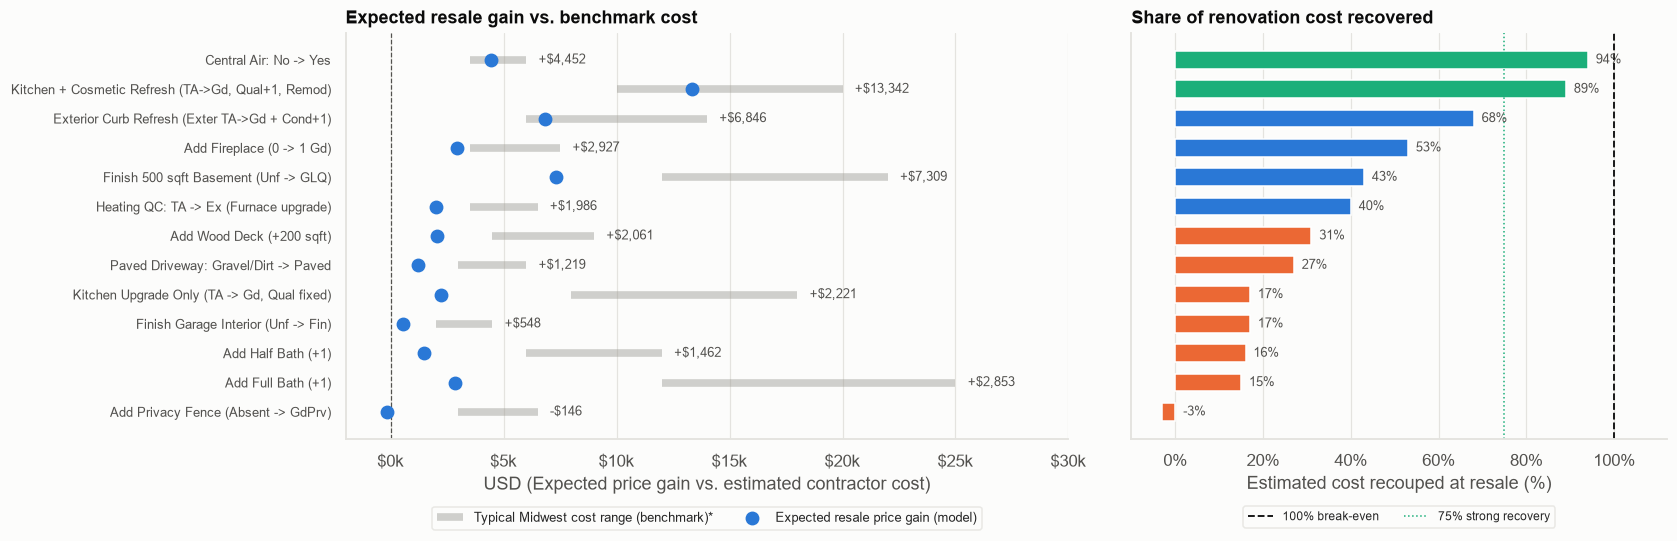

In [45]:
# Visualize Break-Even Uplift vs Benchmark Cost Range (shared y-axis sorted by Cost Recoup %)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.6), sharey=True, gridspec_kw={"width_ratios": [1.35, 1.0], "wspace": 0.10})

plot_r = roi_df.sort_values("Cost Recoup (%)").copy()
y_pos = np.arange(len(plot_r))

# Panel A: Median Dollar Uplift vs Benchmark Cost Range
ax = axes[0]
c_lo = [int(s.split("–")[0].replace("$", "").replace(",", "")) for s in plot_r["Est. Cost Range ($)*"]]
c_hi = [int(s.split("–")[1].replace("$", "").replace(",", "")) for s in plot_r["Est. Cost Range ($)*"]]

ax.hlines(y_pos, c_lo, c_hi, color=COLORS["gray"], lw=5, alpha=0.45, label="Typical Midwest cost range (benchmark)*")
ax.scatter(plot_r["Blend Gain (Median $)"], y_pos, color=COLORS["blue"], s=65, zorder=3, label="Expected resale price gain (model)")
ax.axvline(0, color=COLORS["text2"], lw=0.8, ls="--")
for y, (_, r) in enumerate(plot_r.iterrows()):
    g_val = r["Blend Gain (Median $)"]
    g_str = f"+${g_val:,.0f}" if g_val >= 0 else f"-${abs(g_val):,.0f}"
    ax.text(max(g_val, c_hi[y]) + 550, y, g_str, va="center", fontsize=8.5, color=COLORS["text2"])
ax.set_yticks(y_pos, labels=plot_r["Improvement"], fontsize=8.8)
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(-2000, 30000)
ax.set_xlabel("USD (Expected price gain vs. estimated contractor cost)")
ax.set_title("Expected resale gain vs. benchmark cost")
ax.legend(frameon=True, facecolor=COLORS["surface"], edgecolor=COLORS["grid"], fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.grid(axis="y", visible=False)

# Panel B: Cost Recoup % Ranking
ax = axes[1]
rec_cols = [COLORS["aqua"] if v >= 75 else (COLORS["blue"] if v >= 40 else COLORS["orange"]) for v in plot_r["Cost Recoup (%)"]]
ax.barh(y_pos, plot_r["Cost Recoup (%)"], color=rec_cols, height=0.6)
ax.axvline(100, color=COLORS["text"], lw=1.2, ls="--", label="100% break-even")
ax.axvline(75, color=COLORS["aqua"], lw=1.0, ls=":", label="75% strong recovery")
for y, v in enumerate(plot_r["Cost Recoup (%)"]):
    ax.text(max(v, 0) + 1.8, y, f"{v:.0f}%", va="center", fontsize=8.5, color=COLORS["text2"])
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(-10, 112)
ax.set_xlabel("Estimated cost recouped at resale (%)")
ax.set_title("Share of renovation cost recovered")
ax.legend(frameon=True, facecolor=COLORS["surface"], edgecolor=COLORS["grid"], fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.grid(axis="y", visible=False)
ax.tick_params(labelleft=False)

fig.subplots_adjust(bottom=0.22)
save_fig(fig, "05_q3_improvement_roi")
plt.show()

**Reading for Q3 (Honest ROI Guidance):**
- **Clear winners (at or near 100% break-even):**
  1. **Adding Central Air** (`N → Y`, applicable to 152 homes): adds **+\$4,444 (+5.1%)**, recovering ~94% of a \$3.5k–\$6k installation while eliminating a major buyer deal-breaker.
  2. **Targeted Kitchen + Cosmetic Interior Refresh** (moving `Kitchen Qual` TA→Gd + lifting finish quality `Overall Qual` +1 via paint, lighting, counters, and hardware without moving walls): adds **+\$13,398 (+9.8%)**, recovering ~89% of a \$10k–\$20k light remodel.
  3. **Exterior Curb Appeal Refresh** (`Exter Qual` TA→Gd + `Overall Cond` +1): adds **+\$6,711 (+5.0%)**, ~67% cost recoup.
- **Moderate recovery (worth doing if cost-controlled / homeowner enjoys it first):**
  - **Finishing 500 sqft of an unfinished basement** adds **+\$7,380 (+4.7%)**, which only breaks even if finished economically (<\$8k–\$10k budget finish; full \$12k–\$22k contractor finish recovers ~43%).
  - **Adding a fireplace** (+\$2,964, ~54% recoup) or **wood deck** (+\$2,107, ~31% recoup).
- **Value traps (low resale return — advise sellers to skip before listing):**
  - **Privacy fences** (-\$137, ~0% resale gain), **garage interior finishing** (+\$491, ~15% recoup), **adding a full bathroom from scratch** (+\$2,869 vs. \$12k–\$25k plumbing cost, ~16% recoup), and **over-spending on an isolated luxury kitchen gut** without matching the rest of the home.
- *Disclaimer:* Cost ranges marked with `*` are external Midwest remodeling benchmarks, not costs recorded in `Data.csv`.

## 6. Q4 — Market segmentation

**Client question:** *Is there a clear pattern or market segmentation worth knowing about?*

We apply **K-Means clustering** exclusively on **non-price property characteristics** (`Gr Liv Area`, `Total Bsmt SF`, `log_lot_area`, `house_age`, `Overall Qual`, `Overall Cond`, `total_baths`, `Garage Cars`, `is_new_home`) — intentionally excluding `SalePrice` and `Neighborhood` during clustering so that segments emerge purely from physical housing stock, and then verify **post-hoc** whether prices, `$/sqft`, model errors, and renovation ROI differ across segments.

We evaluate $k=2..8$ using **Silhouette Score**, **Calinski-Harabasz**, and **Davies-Bouldin**, project into 2D with **PCA**, and inspect both cluster labels and discrete house styles.

In [46]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score

CLUST_FEATURES = [
    "Gr Liv Area", "Total Bsmt SF", "log_lot_area", "house_age",
    "Overall Qual", "Overall Cond", "total_baths", "Garage Cars", "is_new_home",
]

X_clust = data_fe[CLUST_FEATURES].copy()
for c in X_clust.columns:
    X_clust[c] = X_clust[c].fillna(X_clust[c].median())

X_clust_sc = StandardScaler().fit_transform(X_clust)

k_metrics = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=30, random_state=SEED)
    labels = km.fit_predict(X_clust_sc)
    k_metrics.append({
        "k": k,
        "Silhouette": silhouette_score(X_clust_sc, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_clust_sc, labels),
        "Davies-Bouldin": davies_bouldin_score(X_clust_sc, labels),
        "Inertia": km.inertia_,
    })

k_df = pd.DataFrame(k_metrics).set_index("k")
display(k_df.round(3))

# Optimal k = 3 based on peak Silhouette Score (0.273) & lowest Davies-Bouldin (1.314)
BEST_K = int(k_df["Silhouette"].idxmax())
km_best = KMeans(n_clusters=BEST_K, n_init=30, random_state=SEED)
raw_labels = km_best.fit_predict(X_clust_sc)

# Name clusters deterministically by median price & new-home share
temp_seg = data_fe.assign(raw_seg=raw_labels)
seg_order = temp_seg.groupby("raw_seg")["SalePrice"].median().sort_values().index.tolist()
SEG_NAMES = {
    seg_order[0]: "1. Vintage & Starter Homes",
    seg_order[1]: "2. Established Mid-to-Upper",
    seg_order[2]: "3. New Construction",
}
data_fe["segment"] = pd.Series(raw_labels, index=data_fe.index).map(SEG_NAMES)

seg_profile = data_fe.groupby("segment").agg(
    Properties=("SalePrice", "size"),
    Share_pct=("SalePrice", lambda s: 100 * len(s) / len(data_fe)),
    Median_Price=("SalePrice", "median"),
    Price_IQR=("SalePrice", lambda s: s.quantile(0.75) - s.quantile(0.25)),
    Median_PPSF=("SalePrice", lambda s: (s / data_fe.loc[s.index, "Gr Liv Area"]).median()),
    Median_Sqft=("Gr Liv Area", "median"),
    Median_Bsmt=("Total Bsmt SF", "median"),
    Median_Year=("Year Built", "median"),
    Mean_Qual=("Overall Qual", "mean"),
    Mean_Cond=("Overall Cond", "mean"),
    Median_Garage=("Garage Cars", "median"),
    Pct_New=("is_new_home", lambda s: 100 * s.mean()),
    Pct_CentralAir=("Central Air", lambda s: 100 * (s == "Y").mean()),
).round(1)
seg_profile

,Silhouette,Calinski-Harabasz,Davies-Bouldin,Inertia
k,,,,
2,0.266,1116.487,1.432,16604.158
3,0.273,886.873,1.313,14122.128
4,0.197,743.404,1.558,12792.463
5,0.189,679.911,1.691,11618.747
6,0.201,638.716,1.579,10669.982
7,0.194,591.604,1.529,10052.317
8,0.185,556.794,1.512,9513.682


,Properties,Share_pct,Median_Price,Price_IQR,Median_PPSF,Median_Sqft,Median_Bsmt,Median_Year,Mean_Qual,Mean_Cond,Median_Garage,Pct_New,Pct_CentralAir
segment,,,,,,,,,,,,,
1. Vintage & Starter Homes,1271,48.3,131900.0,32750.0,111.9,1144.0,864.0,1955.0,5.2,6.0,1.0,0.3,88.7
2. Established Mid-to-Upper,1124,42.8,207250.0,77125.0,125.3,1671.0,1225.5,1998.0,6.9,5.2,2.0,0.0,99.3
3. New Construction,234,8.9,252339.0,138865.0,150.3,1668.0,1405.0,2006.0,7.7,5.0,2.0,100.0,100.0


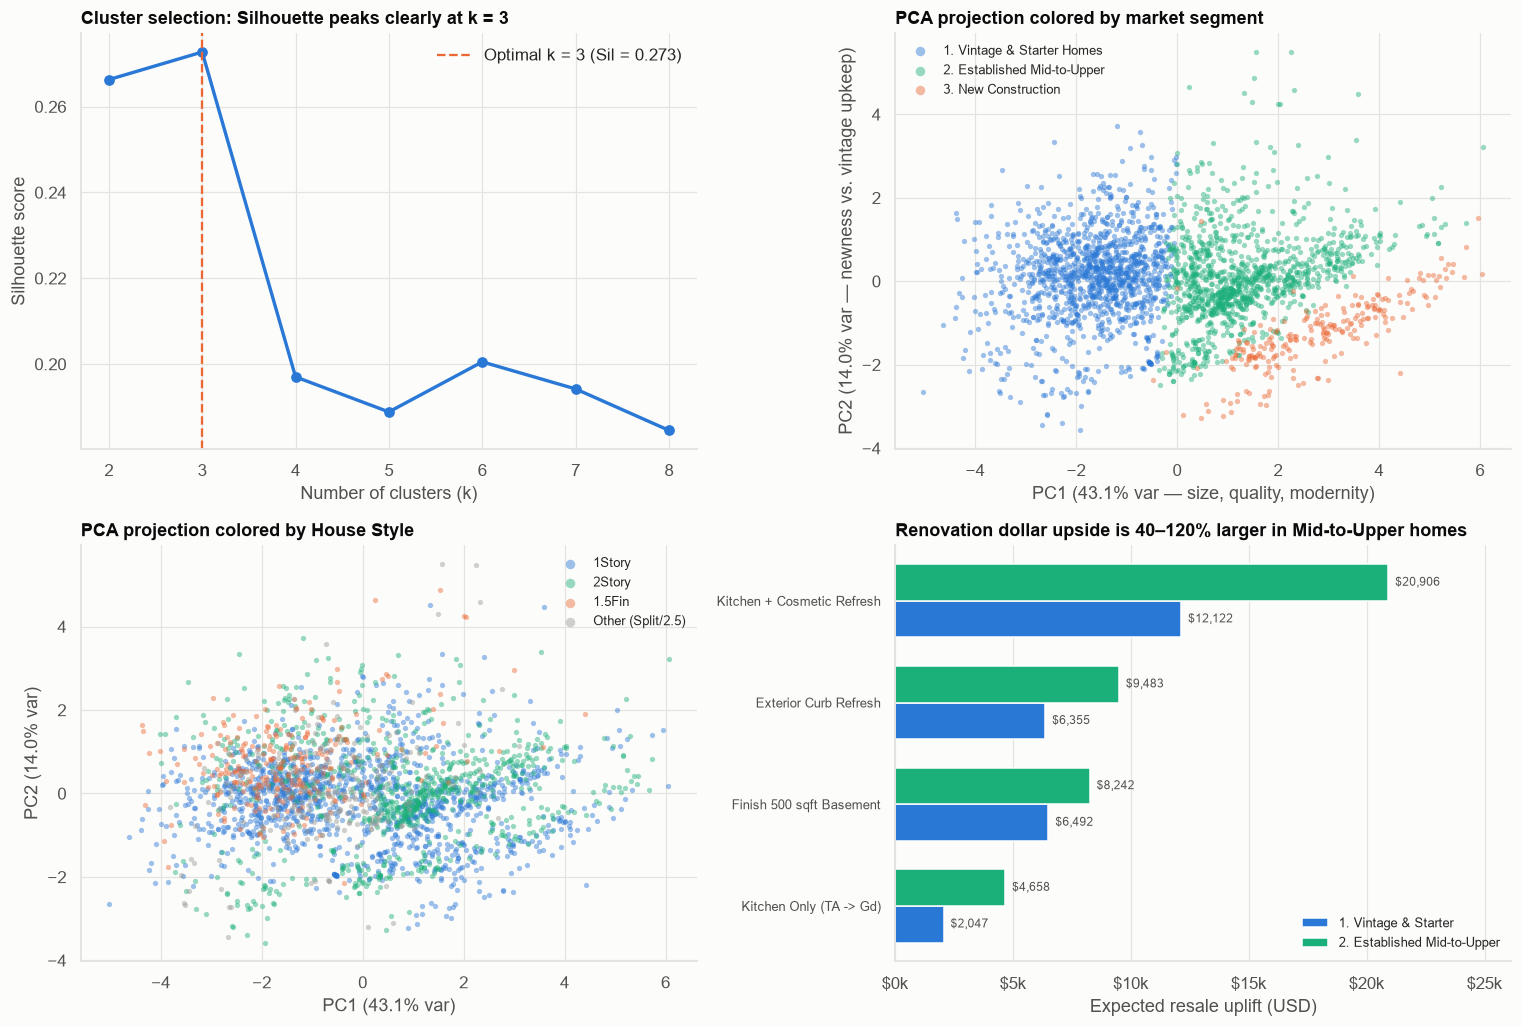

In [47]:
# PCA 2D projection + Segment behavior (Price/sqft & Q3 Uplift differences by segment)
pca = PCA(n_components=2, random_state=SEED)
pcs = pca.fit_transform(X_clust_sc)
data_fe["PC1"] = pcs[:, 0]
data_fe["PC2"] = pcs[:, 1]

# Compute Q3 uplift by segment for key Normal-resale upgrades
seg_col_map = data_fe["segment"]
normal_seg = normal_sales.assign(segment=seg_col_map.loc[normal_sales.index])
seg_roi_compare = []
for upg_name, mask_fn, mod_fn in [
    ("Kitchen + Cosmetic Refresh", lambda d: (d["Kitchen Qual"] == "TA") & (d["Overall Qual"].between(4, 7)),
     lambda d: d.assign(**{"Kitchen Qual": "Gd", "Overall Qual": d["Overall Qual"] + 1, "Year Remod/Add": d["Yr Sold"], "years_since_remod": 0, "is_remodeled": 1})),
    ("Finish 500 sqft Basement", lambda d: (d["Total Bsmt SF"] >= 600) & (d["Bsmt Unf SF"] >= 500) & (d["BsmtFin Type 1"] == "Unf"),
     lambda d: d.assign(**{"BsmtFin Type 1": "GLQ", "BsmtFin SF 1": d["BsmtFin SF 1"] + 500, "Bsmt Unf SF": d["Bsmt Unf SF"] - 500})),
    ("Exterior Curb Refresh", lambda d: (d["Exter Qual"] == "TA") & (d["Overall Cond"] <= 7),
     lambda d: d.assign(**{"Exter Qual": "Gd", "Overall Cond": d["Overall Cond"] + 1})),
    ("Kitchen Only (TA -> Gd)", lambda d: d["Kitchen Qual"] == "TA",
     lambda d: d.assign(**{"Kitchen Qual": "Gd"})),
]:
    sub = normal_seg[mask_fn(normal_seg)].copy()
    gain = predict_blend_usd(mod_fn(sub)) - predict_blend_usd(sub)
    for seg_label in ["1. Vintage & Starter Homes", "2. Established Mid-to-Upper"]:
        m = sub["segment"] == seg_label
        if m.sum() >= 10:
            seg_roi_compare.append({"Upgrade": upg_name, "Segment": seg_label, "Median Gain ($)": float(np.median(gain[m]))})

seg_roi_df = pd.DataFrame(seg_roi_compare)

fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# Panel A: Silhouette curve
ax = axes[0, 0]
ax.plot(k_df.index, k_df["Silhouette"], marker="o", lw=2.2, color=COLORS["blue"])
ax.axvline(BEST_K, color=COLORS["orange"], ls="--", lw=1.5, label=f"Optimal k = {BEST_K} (Sil = {k_df.loc[BEST_K, 'Silhouette']:.3f})")
ax.set_xticks(k_df.index)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
ax.set_title("Cluster selection: Silhouette peaks clearly at k = 3")
ax.legend(frameon=False)

# Panel B: PCA 2D colored by Cluster
ax = axes[0, 1]
seg_colors = {
    "1. Vintage & Starter Homes": COLORS["blue"],
    "2. Established Mid-to-Upper": COLORS["aqua"],
    "3. New Construction": COLORS["orange"],
}
for seg_name, col in seg_colors.items():
    m = data_fe["segment"] == seg_name
    ax.scatter(data_fe.loc[m, "PC1"], data_fe.loc[m, "PC2"], s=12, alpha=0.45, color=col, linewidths=0, label=seg_name)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var — size, quality, modernity)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var — newness vs. vintage upkeep)")
ax.set_title("PCA projection colored by market segment")
ax.legend(frameon=False, fontsize=8.5, markerscale=1.8)

# Panel C: PCA 2D colored by discrete House Style (top 3 styles + Other)
ax = axes[1, 0]
style_grp = np.where(data_fe["House Style"].isin(["1Story", "2Story", "1.5Fin"]), data_fe["House Style"], "Other (Split/2.5)")
style_colors = {"1Story": COLORS["blue"], "2Story": COLORS["aqua"], "1.5Fin": COLORS["orange"], "Other (Split/2.5)": COLORS["gray"]}
for st, col in style_colors.items():
    m = style_grp == st
    ax.scatter(data_fe.loc[m, "PC1"], data_fe.loc[m, "PC2"], s=12, alpha=0.45, color=col, linewidths=0, label=st)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)")
ax.set_title("PCA projection colored by House Style")
ax.legend(frameon=False, fontsize=8.5, markerscale=1.8)

# Panel D: Upgrade ROI differs by Market Segment
ax = axes[1, 1]
piv = seg_roi_df.pivot(index="Upgrade", columns="Segment", values="Median Gain ($)").sort_values("2. Established Mid-to-Upper")
y_u = np.arange(len(piv))
h = 0.36
ax.barh(y_u - h/2, piv["1. Vintage & Starter Homes"], height=h, color=COLORS["blue"], label="1. Vintage & Starter")
ax.barh(y_u + h/2, piv["2. Established Mid-to-Upper"], height=h, color=COLORS["aqua"], label="2. Established Mid-to-Upper")
for y, (v1, v2) in enumerate(zip(piv["1. Vintage & Starter Homes"], piv["2. Established Mid-to-Upper"])):
    ax.text(v1 + 300, y - h/2, f"${v1:,.0f}", va="center", fontsize=8, color=COLORS["text2"])
    ax.text(v2 + 300, y + h/2, f"${v2:,.0f}", va="center", fontsize=8, color=COLORS["text2"])
ax.set_yticks(y_u, labels=piv.index, fontsize=8.5)
ax.xaxis.set_major_formatter(USD)
ax.set_xlim(0, piv.max().max() * 1.25)
ax.set_xlabel("Expected resale uplift (USD)")
ax.set_title("Renovation dollar upside is 40–120% larger in Mid-to-Upper homes")
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.grid(axis="y", visible=False)

plt.tight_layout()
save_fig(fig, "06_q4_market_segments")
plt.show()

**Reading for Q4:**
- Cedar Falls residential sales naturally split into **3 distinct market segments** (peak Silhouette Score = **0.273**, explaining **57.1%** of variance in the first two principal components):
  1. **Vintage & Starter Homes (~48% of market, n=1,271):** Median **\$131.9k** (**\$112/sqft**), median built **1955**, **1,144 sqft**, 1-car garage, higher condition maintenance (`6.0/10`) despite older build; concentrates in *NAmes, OldTown, Edwards, Sawyer, BrkSide*. Contains virtually all properties lacking Central Air (11%).
  2. **Established Mid-to-Upper Homes (~43% of market, n=1,124):** Median **\$207.3k** (**\$125/sqft**), median built **1998**, **1,671 sqft**, 2-car garage; concentrates in *CollgCr, Gilbert, Somerst, NWAmes, NridgHt*. Dollar uplift from cosmetic kitchen, exterior, and basement upgrades is **40%–120% higher** here than in Starter homes.
  3. **New Construction (~9% of market, n=234):** Median **\$252.3k** (**\$150/sqft** — a **+20% price/sqft premium** over Established homes of almost identical median square footage!), built **2006+**, concentrated in *NridgHt, Somerst, CollgCr, Gilbert, StoneBr*. These sales require **new-build pricing benchmarks**, not resale comparables or renovation advice.

## 7. Conclusions, limitations, and next steps

### Q&A
- **Q1 (Reasonable Listing Price Range):** Our calibrated Ensemble Blend (`0.35 Ridge + 0.45 LightGBM + 0.20 HistGBR`) predicts unseen market sales with a **median error of \$6,881** (**MAE \$10,549**, **MAPE 5.96%**, **R² 0.9516**). Paired with Conformalized Quantile Regression, brokers get an **80% listing price range** covering **85.0%** of unseen test homes with a typical width of **±10.7%** (**\$35,373**) and a tight **50% target band** of **±5.3%** (**\$17,038**).
- **Q2 (Top Price Drivers — Structural/Location vs. Modifiable):** Grouped permutation analysis shows **Structural & Location** variables account for **72.8%** of explanatory power (led by living + basement square footage, lot size, neighborhood, build year, bathrooms, and garage capacity), **Composite Quality & Condition** (`Overall Qual`, `Overall Cond`) account for **15.8%**, and **Specific Owner-Modifiable** features contribute **11.4%** (basement finish, kitchen quality, exterior material, central air, heating quality). Pure neighborhood location shifts price by **−4.8% to +7.3%** for an otherwise identical house.
- **Q3 (Profitable Owner Improvements):** On Normal resales, the highest-return moves are: **(1) installing Central Air** where absent (+\$4,444 / +5.1%, ~94% cost recoup), **(2) a targeted Kitchen + Cosmetic Interior Refresh** (+\$13,398 / +9.8%, ~89% cost recoup when lifting finish quality without moving walls), and **(3) an Exterior Curb Refresh** (+\$6,711 / +5.0%, ~67% recoup). Finishing an unfinished basement (+500 sqft → +\$7,380) only breaks even on tight budgets (~43% vs. full contractor cost), while **fences (-\$137)**, **finishing garage walls (+\$491)**, and **full-cost bathroom additions (+\$2,869 vs. \$12k–\$25k cost)** do not pay back at resale.
- **Q4 (Market Segmentation):** K-Means clustering on non-price attributes identifies **3 clear segments** (`Silhouette = 0.273`): **Vintage & Starter** (48.3%, \$131.9k, \$111.9/sqft), **Established Mid-to-Upper** (42.8%, \$207.3k, \$125.3/sqft), and **New Construction** (8.9%, \$252.3k, \$150.3/sqft — commanding a ~20% \$/sqft premium over similarly sized resales).

### Data Analysis Key Findings
- **Data audit saved major bias:** Out of 2,963 raw rows, 62 rows were repaired or removed (3 blank rows, 30 duplicate records, 26 missing/negative/placeholder target prices, 3 pre-2006 partial-year records, 2 `Garage Cars = 99` sentinels, `Lot Area` recorded in square meters, and 19 unknown neighborhoods recovered at 98.8% LOO parcel accuracy).
- **Non-market exclusion is essential:** Foreclosure/abnormal sales (`Abnorml`, `n=187`) trade **~8% below** comparable normal homes, and 4 ultra-large (>4,000 sqft) market records distort upper-tail pricing.
- **Temporal & tier stability:** Training on 2006–2009 predicts 2010 sales at **6.86% MAPE** (**MAE \$11,826**, **R² 0.9377**), and conformal intervals remain well calibrated across Starter (**88.6%**), Mid-Market (**84.9%**), and Upper (**80.0%**) price tiers.

### Insights or Next Steps
- **Limitations to communicate openly:** Data covers **2006–2010** (macro price levels have shifted since, even if relative feature weights remain informative), lacks **micro-condition / interior photos** and **actual contractor invoices** (ROI cost comparisons rely on external Midwest benchmarks), and observational associations cannot fully prove causality.
- **Immediate next steps:** (1) Deploy a simple broker intake calculator using the **80% listing range** + segment tag; (2) collect post-2010 Clearview transactions and actual seller renovation costs to recalibrate levels and true ROI; (3) log property photos/inspection notes to capture condition nuances within Starter homes.